# MurphysBio Employee Attrition Prediction System

> *MurphysBio is a fictional company. Data: IBM HR Analytics Employee Attrition & Performance sample (fictional), distributed by Dicoding.*

This notebook predicts whether an employee will **stay or leave** (*attrition*) and explains which factors are associated with leaving. It follows the CRISP-DM framework end to end: from the business problem, through exploratory analysis and data preparation, to a **Gradient Boosting** classifier tuned with **Optuna** (100 trials), its evaluation against business-relevant benchmarks, an external check against the dataset's original labels, and the export of risk scores and artifacts for a Streamlit app.

**Roadmap**

| # | Section | CRISP-DM phase | Purpose |
|---|---|---|---|
| 1 | Project Overview | Business Understanding | Why attrition matters and which sources frame the problem |
| 2 | Business Understanding | Business Understanding | Problem statements, goals, stakeholders, success criteria (B1–B3, D1–D4) |
| 3 | Setup | — | Imports, version checks and every configurable constant |
| 4 | Data Understanding | Data Understanding | Data acquisition, description, quality checks, EDA and statistical association tests |
| 5 | Data Preparation | Data Preparation | Leakage-safe preparation: before split → split → fit-on-train → model-ready data |
| 6 | Modeling | Modeling | Baseline Gradient Boosting, Optuna tuning (100 trials), model and threshold selection |
| 7 | Evaluation | Evaluation | Test-set evaluation against naive and rule-based benchmarks, then a second iteration that addresses the process review |
| 8 | Deployment | Deployment | Refit on all labeled data, score employees without a recorded outcome, external validation, artifacts for the Streamlit app |
| 9 | Conclusion & Recommendations | Evaluation (summary) | Answers to the problem statements, recommendations and limitations |

**Deliberate deviations from the textbook CRISP-DM order**

1. **Statistical association tests sit in Data Understanding (Section 4.5).** The Mann-Whitney U, Welch t and chi-square tests describe the data; the chi-square screen used for feature selection is repeated on the training split only (Section 5.6).
2. **Row-wise feature engineering happens before the train/test split (Section 5.2).** Each engineered feature uses only values from the same employee row, so no information crosses the split.
3. **Employees without a recorded outcome are kept (Section 5.3).** They cannot be used for training or testing, but they are exactly the population the model is meant to score (Section 8.2), and their outcomes in IBM's original file make them an external validation set (Section 8.3).
4. **The test set is used a second time (Section 7.9).** Iteration 2 makes every choice on the training split with cross-validation, then evaluates the final candidate on the same test set; that second look is reported with bootstrap confidence intervals and is backed by the external validation in Section 8.3.

## 1. Project Overview

**Every employee who leaves takes skills, client relationships and team knowledge out of the door, and replacing that person is expensive.**

Gallup estimates that replacing an individual employee costs between one-half and two times that employee's annual salary, and describes this estimate as conservative (McFeely & Wigert, 2019). Much of that loss is considered preventable: in the same study, 52% of employees who left voluntarily said their manager or organization could have done something to keep them. Meta-analytic research on voluntary turnover shows that leaving is driven by a mix of job attitudes, the work environment, pay and personal circumstances rather than one single factor (Rubenstein et al., 2018).

This project treats attrition as a **binary classification** problem (*stayed* vs. *left*) and uses historical HR records to (1) describe which factors are associated with leaving and (2) give HR a ranked list of employees at elevated risk, so that retention conversations can start before a resignation letter arrives.

**About the data.** The primary dataset is Dicoding's `employee_data.csv` (Dicoding Academy, n.d.). It is a copy of IBM's fictional *HR Analytics Employee Attrition & Performance* dataset (IBM, n.d.; Pavansubhash, 2017), with an `EmployeeId` column added and the attrition outcome removed for 412 of the 1,470 employees. A row-by-row comparison carried out during the revision of this notebook confirmed that all 1,470 employees match IBM's original file exactly on every shared column, and that the 1,058 outcomes Dicoding kept agree 100% with IBM's. IBM's file is therefore used as a secondary reference: it supplies the withheld outcomes for the external validation in Section 8.3 and nothing else. Because the data are fictional, findings illustrate the method and must not be read as evidence about any real company.

**About the company.** For storytelling, the employer is named **MurphysBio**, a *fictional* pharmaceutical and life-sciences company. The framing follows the data rather than the other way round: the largest job roles are Sales Executive (326), Research Scientist (292), Laboratory Technician (259), Manufacturing Director (145) and Healthcare Representative (131); most employees studied Life Sciences (606) or Medical (464); and the company has three departments, Research & Development (961), Sales (446) and Human Resources (63). This profile matches a drug or biotech company that researches, manufactures and sells products to healthcare providers. The name, industry and any location are illustrative only; the data contain no company name, industry, country or dates.

### 1.1 References

**Industry reports and official documents**

- McFeely, S., & Wigert, B. (2019, March 13). *This fixable problem costs U.S. businesses $1 trillion*. Gallup. https://www.gallup.com/workplace/247391/fixable-problem-costs-businesses-trillion.aspx
- Uniform Guidelines on Employee Selection Procedures (1978), 29 C.F.R. § 1607.4 (2024). https://www.govinfo.gov/content/pkg/CFR-2024-title29-vol4/pdf/CFR-2024-title29-vol4-sec1607-4.pdf

**Scientific papers and books**

- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). https://doi.org/10.1145/3292500.3330701
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Hosmer, D. W., Jr., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). Wiley. https://doi.org/10.1002/9781118548387
- Rubenstein, A. L., Eberly, M. B., Lee, T. W., & Mitchell, T. R. (2018). Surveying the forest: A meta-analysis, moderator investigation, and future-oriented discussion of the antecedents of voluntary employee turnover. *Personnel Psychology, 71*(1), 23–65. https://doi.org/10.1111/peps.12226
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), Article e0118432. https://doi.org/10.1371/journal.pone.0118432

**Data and software**

- Dicoding Academy. (n.d.). *employee_data.csv* [Data set]. GitHub. https://github.com/dicodingacademy/dicoding_dataset/tree/main/employee
- IBM. (n.d.). *emp_attrition.csv* [Data set]. In *employee-attrition-aif360*. GitHub. https://github.com/IBM/employee-attrition-aif360
- Pavansubhash. (2017). *IBM HR Analytics Employee Attrition & Performance* [Data set]. Kaggle. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

## 2. Business Understanding

### 2.1 Problem Statements

1. **PS1 — Which factors are associated with employees leaving?** HR currently has no evidence-based view of which working conditions, job characteristics or pay patterns separate leavers from stayers.
   *What is at stake:* retention budgets spent on the wrong levers (e.g. across-the-board raises when overtime is the real pressure point).
2. **PS2 — Can the risk of leaving be predicted for employees whose outcome is not yet recorded?** 412 employees in the data have no recorded attrition status. HR needs to know which of them deserve a retention conversation first.
   *What is at stake:* each avoidable departure costs an estimated 0.5–2× annual salary (McFeely & Wigert, 2019).
3. **PS3 — Was the departure voluntary or initiated by the company?** The project scope includes this distinction, but neither Dicoding's nor IBM's file contains a reason for leaving, so PS3 cannot be answered with these data. It is kept to document the data requirement for the next iteration (Recommendation 6).

### 2.2 Goals

| Goal | Answers | Success criteria |
|---|---|---|
| **G1** — Identify and quantify the factors most strongly associated with attrition, with statistical support and clear direction of effect | PS1 | B1, D4 |
| **G2** — Build a Gradient Boosting model that ranks employees by attrition risk better than a simple business rule, and score the 412 employees without a recorded outcome | PS2 | B2, D1, D2, D3 |
| **G3** — Separate voluntary from involuntary attrition | PS3 | B3 (not possible with these data) |

### 2.3 Situation Assessment

*The stakeholder map below is a proposal based on common HR-analytics practice; the dataset does not name real roles.*

| Stakeholder | Decision supported | Outputs used |
|---|---|---|
| HR Business Partners | Whom to invite for a retention / stay interview this quarter | Risk-score list (Section 8.2), top drivers (Section 7.5) |
| Department heads | Workload and overtime planning, team-level retention actions | Attrition rates by department and role (Section 4.4), Streamlit dashboard (Section 8.5) |
| HR Director / Compensation team | Pay-band and career-path policy | Income and job-level findings (Sections 4.4.6–4.4.10, 4.5.1) |
| Data / People Analytics team | Model maintenance, monitoring and retraining | Pipeline, Optuna results, model metadata (Sections 6 and 8) |

**Resources:** one CSV with 1,470 employees × 35 columns (Dicoding), IBM's original file for external validation; Python ecosystem (pandas, scikit-learn, Optuna); Streamlit for the HR dashboard and the predictive prototype (Section 8.5).

**Requirements, assumptions and constraints**

- The model must only use information that is known *before* an employee leaves (no post-exit data).
- In the MurphysBio storyline, the 412 employees without a label are treated as employees whose outcome has not yet been recorded. In reality, Dicoding withheld these labels from IBM's original file, where 58 of the 412 left (14.1%) and 354 stayed; Section 8.3 uses those outcomes to validate the deployed model.
- The data are a single snapshot: there is no time dimension, so the model estimates *who* is at risk, not *when*.
- Sensitive attributes (Gender, MaritalStatus, Age) are present. Their use in an HR decision tool must be cleared with HR/legal (toggle `EXCLUDED_FEATURES` in Section 3.2; fairness monitoring in Section 8.4).

**Risks and contingencies**

| Risk | Contingency |
|---|---|
| Class imbalance (≈17% leavers) makes accuracy look good even for a useless model | Evaluate with recall, precision, F2 and average precision against a majority-class and a rule-based benchmark |
| Small sample (1,058 labeled rows) makes test metrics noisy | Stratified split, 10-fold cross-validation for all model choices, test set used once, external validation on 412 further employees |
| Model used to penalize employees flagged as "at risk" | Position scores as a prompt for supportive conversations; document intended use in Section 8.4 |
| Fictional data limits external validity | State limitation explicitly (Section 9.6); retrain on real HR data before use |

### 2.4 Success Criteria

All criteria are fixed **before modeling**. Benchmarks are derived from simple statistics of the labeled data and from published rules of thumb.

**Business criteria**

| ID | Criterion |
|---|---|
| **B1** | The top drivers of attrition are reported with direction of effect and a statistical test, in language HR can act on |
| **B2** | Every employee without a recorded outcome receives a risk probability and a flag, exported in a format the Streamlit app can read |
| **B3** | Voluntary and involuntary attrition can be analyzed separately (requires a reason-for-leaving field, which the data do not contain) |

**Data-mining criteria** (evaluated on the held-out test set unless stated otherwise)

| ID | Criterion | Rationale |
|---|---|---|
| **D1** | ROC AUC ≥ 0.75 | An ROC AUC of 0.70–0.80 is conventionally read as acceptable discrimination and 0.80–0.90 as excellent (Hosmer et al., 2013); 0.75 adds a safety margin above the lower bound for a small test set |
| **D2** | F2 score higher than the rule "flag everyone who works overtime" on the same test set | OverTime is the strongest single association (Section 4.5.2); on all labeled data this rule reaches recall 0.547, precision 0.319, F2 0.479. A model that cannot beat it adds no value |
| **D3** | Average precision ≥ 2 × the share of leavers (≈ 0.34) | A random ranking scores roughly the prevalence (≈ 0.17); a two-fold lift is the proposed minimum for a ranking HR would act on |
| **D4** | \|CV ROC AUC − test ROC AUC\| ≤ 0.05 | Checks that cross-validation results generalize and the model is stable |

**Metric definitions**

- *Recall* (sensitivity): share of actual leavers that the model flags. Missing a leaver is the most expensive error, so recall is weighted heavily.
- *Precision*: share of flagged employees who actually leave. Low precision wastes HR time.
- *F2*: harmonic mean of precision and recall that weighs recall twice as much as precision.
- *ROC AUC*: probability that a random leaver gets a higher risk score than a random stayer (0.5 = random).
- *Average precision (PR-AUC)*: area under the precision-recall curve; more informative than ROC AUC when the positive class is rare (Saito & Rehmsmeier, 2015).

### 2.5 Solution Approach

| Approach | Technique | Goal |
|---|---|---|
| Descriptive | Attrition rates by segment, distribution plots, correlation analysis | G1 |
| Statistical | Mann-Whitney U and Welch t-tests with Benjamini-Hochberg adjustment (14 continuous features), chi-square test with Cramér's V (16 categorical and coded features) | G1 |
| Predictive | Gradient Boosting classifier (Friedman, 2001) in a scikit-learn pipeline, tuned with Optuna's TPE sampler (Akiba et al., 2019) over 100 trials, decision threshold optimized for F2 | G2 |
| Explanatory | Permutation importance on the test set, cross-checked with EDA rates for direction of effect | G1, G2 |

## 3. Setup

This section is not a CRISP-DM phase. It loads every library once and gathers all configurable values in one place, so the notebook can be re-run from top to bottom (**Restart & Run All**) with reproducible results.

**Environment.** Locally, use Python 3.13 (the saved model requires scikit-learn 1.6.1) and install the pinned dependencies, including the notebook extras, with `pip install -r requirements-dev.txt`. Google Colab does not ship Optuna, so the first code cell installs it; locally, `requirements-dev.txt` already includes it. The stored outputs come from a full Colab run with Python 3.13.18, pandas 2.2.3, NumPy 2.4.6, SciPy 1.16.3, scikit-learn 1.6.1, Optuna 5.1.0, Matplotlib 3.10.0 and seaborn 0.13.2.

### 3.1 Imports and Version Check

In [1]:
# Google Colab does not ship Optuna; locally, use requirements-dev.txt instead.
%pip install -q "optuna>=5.0"

In [2]:
import json
import sys
from collections.abc import Sequence
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from typing import Any

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    fbeta_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    FixedThresholdClassifier,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Minimum versions the code relies on (e.g. TunedThresholdClassifierCV needs
# scikit-learn 1.5). Exact pins live in requirements.txt.
MIN_PYTHON = (3, 12)
MIN_VERSIONS = {
    "pandas": (2, 2),
    "numpy": (2, 0),
    "scipy": (1, 11),
    "scikit-learn": (1, 5),
    "optuna": (4, 0),
    "matplotlib": (3, 8),
    "seaborn": (0, 13),
}


def parse_version(raw: str) -> tuple[int, ...]:
    """Convert a version string such as ``'1.9.1'`` into ``(1, 9)``.

    Only the major and minor parts are compared; suffixes such as ``rc1``
    are ignored.

    Args:
        raw: Version string reported by the installed package.

    Returns:
        Tuple with the numeric major and minor version.
    """
    return tuple(int(part) for part in raw.split(".")[:2] if part.isdigit())


outdated = [
    f"{package} {version(package)} < {'.'.join(map(str, minimum))}"
    for package, minimum in MIN_VERSIONS.items()
    if parse_version(version(package)) < minimum
]
if sys.version_info < MIN_PYTHON:
    outdated.append(
        f"Python {sys.version.split()[0]} < {'.'.join(map(str, MIN_PYTHON))}"
    )
if outdated:
    raise RuntimeError(
        "Please upgrade (pip install -r requirements.txt): " + "; ".join(outdated)
    )

print(f"Python {sys.version.split()[0]}")
for package in MIN_VERSIONS:
    print(f"{package:<13} {version(package)}")

Python 3.13.18
pandas        2.2.3
numpy         2.4.6
scipy         1.16.3
scikit-learn  1.6.1
optuna        5.1.0
matplotlib    3.10.0
seaborn       0.13.2


### 3.2 Configuration

Every constant used later in the notebook is defined here, grouped by topic. Changing a value here (for example the number of Optuna trials or the list of excluded features) is the only edit needed to run an experiment variant.

In [3]:
# --- Reproducibility ---
RANDOM_STATE = 126

# --- Branding (fictional company, see Section 1) ---
COMPANY_NAME = "MurphysBio"
DATA_DISCLAIMER = (
    f"{COMPANY_NAME} is a fictional company. Data: IBM HR Analytics Employee "
    "Attrition sample (fictional)."
)

# --- Paths (relative to the project root; created on demand) ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_URL = (
    "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/"
    "refs/heads/main/employee/employee_data.csv"
)
# IBM's original file: used only for external validation (Section 8.3).
IBM_DATA_URL = (
    "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/"
    "master/data/emp_attrition.csv"
)
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "employee_data.csv"
IBM_RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ibm_emp_attrition.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODEL_DIR = ARTIFACTS_DIR / "trained_models"  # files loaded by the Streamlit app
TUNING_DIR = ARTIFACTS_DIR / "tuning"  # Optuna trial logs (experiment records)
MODEL_PATH = MODEL_DIR / "gradient_boosting_pipeline.joblib"
MODEL_METADATA_PATH = MODEL_DIR / "model_metadata.json"
FEATURE_SCHEMA_PATH = MODEL_DIR / "feature_schema.json"  # Streamlit input forms
MODEL_CARD_PATH = MODEL_DIR / "model_card.json"  # evaluation summary for the app
TUNING_RESULTS_PATH = TUNING_DIR / "optuna_tuning_results.json"  # flat JSON trial log
TUNING_BEST_PATH = TUNING_DIR / "optuna_best_params.json"  # flat JSON best trial
DASHBOARD_CSV_PATH = PROCESSED_DIR / "employee.csv"  # Streamlit dashboard input
RISK_SCORES_PATH = PROCESSED_DIR / "employee_risk_scores.csv"

# --- Data schema ---
TARGET = "Attrition"
ID_COL = "EmployeeId"
ATTRITION_LABELS = {0: "No (stayed)", 1: "Yes (left)"}
NOMINAL_COLS = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "OverTime",
]
# Ordered survey/grade scales stay numeric so tree splits respect their order.
ORDINAL_COLS = [
    "Education",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobLevel",
    "JobSatisfaction",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "StockOptionLevel",
    "WorkLifeBalance",
]
# Official labels from the IBM HR Analytics data dictionary.
SATISFACTION_LABELS = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"}
ORDINAL_LABELS = {
    "JobSatisfaction": SATISFACTION_LABELS,
    "EnvironmentSatisfaction": SATISFACTION_LABELS,
    "WorkLifeBalance": {1: "Bad", 2: "Good", 3: "Better", 4: "Best"},
    "JobLevel": {level: f"Level {level}" for level in range(1, 6)},
}
ENGINEERED_COLS = [
    "MaxYearsSinceChange",
    "ExperienceOutsideCompany",
    "TrainingsPerYearAtCompany",
]

# --- EDA thresholds ---
SKEW_LIMIT = 0.75  # |skew| above this is flagged as strongly skewed
CORR_THRESHOLD = 0.6  # |Pearson r| above this is reported as a strong pair
ALPHA = 0.05  # significance level for the statistical tests

# --- Feature-selection toggles ---
# Sensitive attributes can be excluded for a fairness-aware variant.
EXCLUDED_FEATURES: tuple[str, ...] = ()  # e.g. ("Gender", "MaritalStatus", "Age")
DROP_CHI2_NOT_SIGNIFICANT = True  # chi-square screen on the TRAIN split only

# --- Split & validation ---
TEST_SIZE = 0.15
CV_FOLDS = 10
CV_SCORING = {"average_precision": "average_precision", "roc_auc": "roc_auc"}

# --- Optuna hyperparameter search (Gradient Boosting) ---
N_TRIALS = 100
OPTUNA_METRIC = (
    "average_precision"  # optimized with CV_FOLDS-fold CV on the train split
)
GB_SEARCH_SPACE: dict[str, Any] = {
    "n_estimators": (100, 600, 50),  # (low, high, step)
    "learning_rate": (0.005, 0.3),  # sampled on a log scale
    "max_depth": (2, 6),
    "min_samples_leaf": (1, 50),  # sampled on a log scale
    "subsample": (0.6, 1.0),  # < 1.0 = stochastic gradient boosting
    "max_features": ("sqrt", "log2", None),
}

# --- Decision threshold & success criteria (Section 2.4) ---
F_BETA = 2.0  # recall weighted twice as much as precision
MIN_TEST_ROC_AUC = 0.75  # D1: acceptable discrimination (Hosmer et al., 2013) + margin
AP_LIFT_TARGET = 2.0  # D3: average precision >= 2 x prevalence
MAX_CV_TEST_GAP = 0.05  # D4: tolerated |CV ROC AUC - test ROC AUC|
PERMUTATION_REPEATS = 20

# --- Fairness monitoring (Section 8.3) ---
# Four-fifths rule of thumb (29 C.F.R. 1607.4(D)): each group's flag rate should be
# at least 80% of the highest group's rate, otherwise HR/legal review the model.
FAIRNESS_MIN_RATIO = 0.8
AGE_BANDS = [17, 29, 39, 49, 60]  # bin edges -> 18-29, 30-39, 40-49, 50-60

# --- Iteration 2 (Section 7.9) ---
CV_REPEATS = 5  # repeated stratified CV: CV_FOLDS x CV_REPEATS fits per candidate
SENSITIVE_FEATURES = ("Gender", "MaritalStatus", "Age")
SIMPLICITY_TOLERANCE = 0.005  # drop a feature group if mean CV AP falls by <= this
MAX_AP_LOSS_FOR_FAIRNESS = (
    0.02  # drop sensitive features if mean CV AP falls by <= this
)
CALIBRATION_METHOD = "sigmoid"  # Platt scaling; robust with ~150 training leavers
CALIBRATION_CV = 5  # inner folds used by CalibratedClassifierCV
REVIEW_CAPACITY_SHARE = 0.20  # HR reviews the top 20% of each scoring round
CAPACITY_GRID = (0.10, 0.20, 0.30, 0.40)
N_BOOTSTRAP = 1000  # resamples for test-set confidence intervals

sns.set_theme(style="whitegrid")

## 4. Data Understanding

### 4.1 Data Acquisition

The data are downloaded once from Dicoding's public GitHub repository and cached locally in `data/raw/`, so later runs work offline and always use the same file.

| Dataset | Granularity | Rows | Columns | Content |
|---|---|---|---|---|
| `employee_data.csv` | One row per employee (single snapshot, no dates) | 1,470 | 35 | Demographics, job characteristics, pay, tenure, satisfaction surveys and the target `Attrition` (1 = left, 0 = stayed, empty = unknown) |

In [4]:
def load_employee_data(url: str, cache_path: Path) -> pd.DataFrame:
    """Load the employee dataset, downloading it only on the first run.

    Caching the raw file makes the notebook reproducible even if the remote
    file changes or the machine is offline.

    Args:
        url: Public URL of the raw CSV file.
        cache_path: Local path where the raw CSV is stored.

    Returns:
        The raw employee data, one row per employee.
    """
    if not cache_path.exists():
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        pd.read_csv(url).to_csv(cache_path, index=False)
    return pd.read_csv(cache_path)


employee_data = load_employee_data(DATA_URL, RAW_DATA_PATH)
print(f"Loaded {employee_data.shape[0]:,} rows x {employee_data.shape[1]} columns.")

Loaded 1,470 rows x 35 columns.


### 4.2 Data Description

The structure check below lists every column with its data type and number of non-empty values. Only `Attrition` has empty values: **412 employees (28%) have no recorded outcome**.

In [5]:
# Column names, data types and non-empty counts
employee_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   object 
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   object 
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   object 
 9   EmployeeCount             1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   object 
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-null   int64  
 14  JobLevel

In [6]:
print(
    f"The data contain {employee_data.shape[1]} columns and "
    f"{employee_data.shape[0]:,} rows, with "
    f"{employee_data.isna().sum().sum()} missing values in total."
)
employee_data.head()

The data contain 35 columns and 1,470 rows, with 412 missing values in total.


,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,...,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,...,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,...,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,...,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,...,2,80,3,20,2,3,5,3,0,2


Summary statistics of the numeric columns. `Attrition` has a mean of 0.169 over 1,058 labeled rows, i.e. **16.9% of employees with a known outcome left**. `EmployeeCount` and `StandardHours` have a standard deviation of 0: they carry no information.

In [7]:
# Summary statistics of the numeric columns
employee_data.describe().T

,count,mean,std,min,25%,50%,75%,max
EmployeeId,1470.0,735.500000,424.496761,1.0,368.25,735.5,1102.75,1470.0
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
Attrition,1058.0,0.169187,0.375094,0.0,0.00,0.0,0.00,1.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0


Summary of the text (categorical) columns, followed by the frequency of every category. `Over18` has a single value (`Y`) and is therefore uninformative.

In [8]:
categorical_cols = employee_data.select_dtypes(exclude="number").columns.tolist()

frequency_table = pd.concat(
    [
        employee_data[col]
        .value_counts()
        .rename_axis("Unique Value")
        .reset_index(name="Frequency")
        .assign(Variable=col)
        for col in categorical_cols
    ],
    ignore_index=True,
)

display(employee_data[categorical_cols].describe())
display(frequency_table)

,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470
unique,3,3,6,2,9,3,1,2
top,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1043,961,606,882,326,673,1470,1054


,Unique Value,Frequency,Variable
0,Travel_Rarely,1043,BusinessTravel
1,Travel_Frequently,277,BusinessTravel
2,Non-Travel,150,BusinessTravel
3,Research & Development,961,Department
4,Sales,446,Department
5,Human Resources,63,Department
6,Life Sciences,606,EducationField
7,Medical,464,EducationField
8,Marketing,159,EducationField
9,Technical Degree,132,EducationField


**Data dictionary (coded columns).** Several numeric columns are ordered survey scales or grades, not measurements. Their official labels are:

| Column | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Education | Below College | College | Bachelor | Master | Doctor |
| EnvironmentSatisfaction, JobSatisfaction, JobInvolvement, RelationshipSatisfaction | Low | Medium | High | Very High | — |
| WorkLifeBalance | Bad | Good | Better | Best | — |
| PerformanceRating | Low | Good | Excellent | Outstanding | — |
| JobLevel, StockOptionLevel | ordered grades (StockOptionLevel starts at 0) | | | | |

`MonthlyIncome`, `DailyRate`, `HourlyRate` and `MonthlyRate` are expressed in **monetary units**: neither IBM nor Dicoding documents the currency or how the rate columns are defined, so these values are only compared relative to each other.

### 4.3 Data Quality Verification

Three checks decide what Data Preparation must handle: missing values, columns without variance and duplicated employees.

In [9]:
quality_report = pd.DataFrame(
    {
        "missing": employee_data.isna().sum(),
        "unique_values": employee_data.nunique(dropna=False),
    }
).query("missing > 0 or unique_values <= 1")

display(quality_report)
print(
    f"Duplicated rows (ignoring {ID_COL}): "
    f"{employee_data.drop(columns=ID_COL).duplicated().sum()}"
)
print(f"Duplicated {ID_COL} values: {employee_data[ID_COL].duplicated().sum()}")

,missing,unique_values
Attrition,412,3
EmployeeCount,0,1
Over18,0,1
StandardHours,0,1


Duplicated rows (ignoring EmployeeId): 0
Duplicated EmployeeId values: 0


**Result.** Only `Attrition` is missing (412 rows); `EmployeeCount`, `Over18` and `StandardHours` are constant; there are no duplicated rows or IDs. The missing labels are **not** imputed: guessing an outcome would inject assumptions into the target. Instead, those employees become the scoring population in Section 8.2. Their true outcomes exist in IBM's original file (Section 1), which Section 8.3 uses for an external validation.

### 4.4 Exploratory Data Analysis (EDA)

The EDA answers four questions, each linked to a goal:

| # | Question | Goal |
|---|---|---|
| Q1 | How large is attrition, and does it differ across departments and gender? | G1 |
| Q2 | Do work-life balance and job satisfaction separate leavers from stayers? | G1 |
| Q3 | How does pay relate to department, role, experience and attrition? | G1 |
| Q4 | Which numeric features are redundant or skewed, and what does that mean for modelling? | G2 |

A note on reading the charts: an **attrition rate** is the share of employees *within a group* who left (e.g. 20% of Sales staff). A **share of leavers** is the share of all leavers who belong to a group (e.g. 37% of leavers work in Sales). Large groups dominate shares even when their rate is average, so conclusions about risk are drawn from rates.

#### 4.4.1 Plotting Helpers

Reusable functions keep every chart consistent and avoid copy-pasted plotting code.

In [10]:
def plot_bar(
    data: pd.DataFrame,
    x_col: str,
    y_col: str | None = None,
    *,
    hue: str | None = None,
    order: Sequence[Any] | None = None,
    hue_order: Sequence[Any] | None = None,
    title: str = "",
    xlabel: str = "",
    ylabel: str = "",
    ax: plt.Axes | None = None,
) -> plt.Axes:
    """Draw a bar chart (or a count chart when ``y_col`` is None) with value labels.

    Args:
        data: Data to plot.
        x_col: Column on the x-axis.
        y_col: Column with bar heights. If None, rows are counted instead.
        hue: Optional column that splits each bar by color.
        order: Optional order of the x-axis categories.
        hue_order: Optional order of the hue categories.
        title: Chart title.
        xlabel: X-axis label.
        ylabel: Y-axis label.
        ax: Axes to draw on. Defaults to the current axes.

    Returns:
        The axes containing the chart.
    """
    ax = ax or plt.gca()
    if y_col is None:
        sns.countplot(
            data=data, x=x_col, hue=hue, order=order, hue_order=hue_order, ax=ax
        )
    else:
        sns.barplot(
            data=data,
            x=x_col,
            y=y_col,
            hue=hue,
            order=order,
            hue_order=hue_order,
            errorbar=None,
            ax=ax,
        )
    for container in ax.containers:
        # Rounded (not truncated) labels, so 25.9 is shown as 26.
        ax.bar_label(container, fmt="{:,.0f}")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.tick_params(axis="x", labelrotation=45)
    return ax


def plot_pie(
    values: pd.Series, *, title: str = "", ax: plt.Axes | None = None
) -> plt.Axes:
    """Draw a pie chart of category shares.

    Args:
        values: Categorical values; each slice is one category's share.
        title: Chart title.
        ax: Axes to draw on. Defaults to the current axes.

    Returns:
        The axes containing the chart.
    """
    ax = ax or plt.gca()
    counts = values.value_counts()
    ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(title)
    ax.axis("equal")
    return ax


def attrition_rate_table(data: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    """Compute the share of stayers and leavers within each group.

    Rows without a known outcome are excluded, so every percentage is an
    attrition rate among employees whose status is known.

    Args:
        data: Employee data containing ``TARGET`` and ``group_cols``.
        group_cols: Columns that define the groups.

    Returns:
        Long table with ``group_cols``, the outcome label and ``Percentage``.
    """
    return (
        data.dropna(subset=[TARGET])
        .groupby(group_cols, observed=True)[TARGET]
        .value_counts(normalize=True)
        .mul(100)
        .rename("Percentage")
        .reset_index()
        .assign(**{TARGET: lambda d: d[TARGET].map(ATTRITION_LABELS)})
    )


def plot_attrition_rate_by_gender(
    data: pd.DataFrame, group_col: str, value_labels: dict[int, str] | None = None
) -> None:
    """Plot attrition rates by ``group_col``, one panel per gender.

    Args:
        data: Employee data.
        group_col: Column whose categories form the x-axis.
        value_labels: Optional mapping from codes to readable labels; also
            fixes the x-axis order.
    """
    rates = attrition_rate_table(data, ["Gender", group_col])
    order = None
    if value_labels:
        rates[group_col] = rates[group_col].map(value_labels)
        order = list(value_labels.values())

    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
    for ax, gender in zip(axes, ("Male", "Female"), strict=True):
        plot_bar(
            rates[rates["Gender"] == gender],
            group_col,
            "Percentage",
            hue=TARGET,
            order=order,
            hue_order=list(ATTRITION_LABELS.values()),
            title=f"Attrition rate by {group_col} ({gender})",
            xlabel=group_col,
            ylabel="Share of employees in group (%)",
            ax=ax,
        )
    fig.tight_layout()
    plt.show()


# Employees with a known outcome; used wherever attrition is compared.
labeled_data = employee_data.dropna(subset=[TARGET])

#### 4.4.2 Overall Attrition and Leavers by Department (Q1)

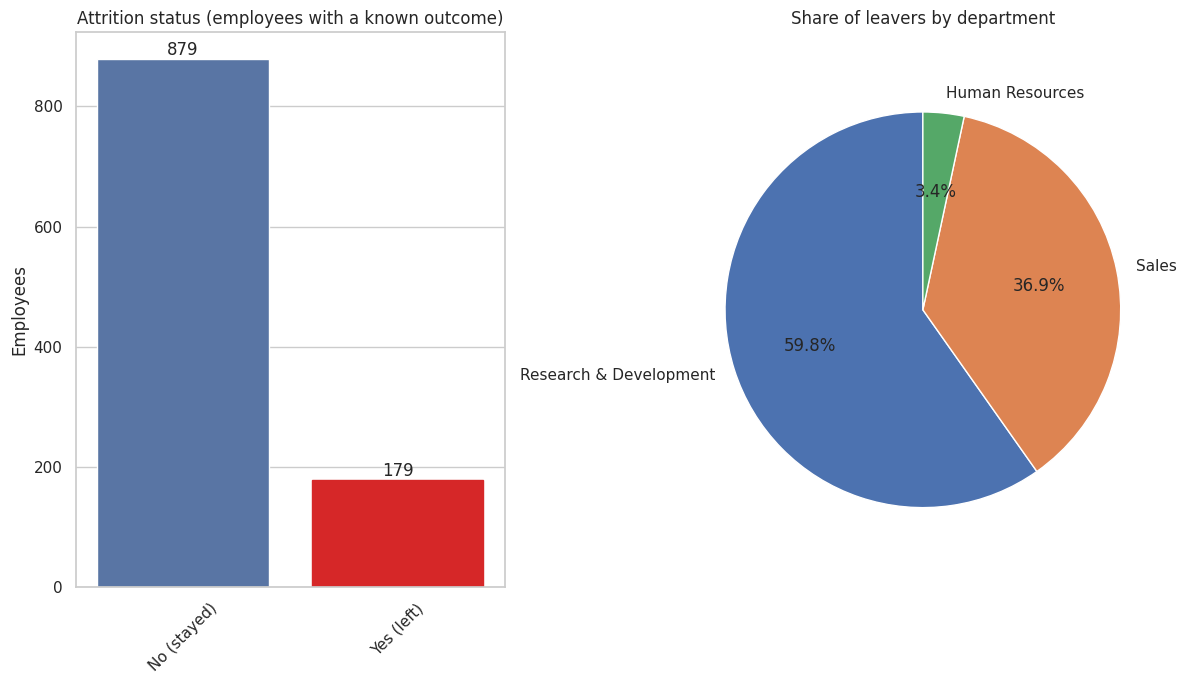

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

status_order = list(ATTRITION_LABELS.values())
plot_bar(
    labeled_data.assign(Status=labeled_data[TARGET].map(ATTRITION_LABELS)),
    "Status",
    order=status_order,
    title="Attrition status (employees with a known outcome)",
    ylabel="Employees",
    ax=axes[0],
)
axes[0].containers[0][1].set_color("tab:red")  # highlight the leavers

plot_pie(
    labeled_data.loc[labeled_data[TARGET] == 1, "Department"],
    title="Share of leavers by department",
    ax=axes[1],
)

fig.tight_layout()
plt.show()

**Insight 1: About one in six employees with a known outcome left; Sales has the highest attrition rate, not R&D.**

- **Finding.** 179 of 1,058 employees with a known outcome left (**16.9%**); 879 stayed. Of the 179 leavers, 59.8% worked in Research & Development, 36.9% in Sales and 3.4% in Human Resources.
- **Fact check.** The pie shows *shares of leavers*, which mostly mirror department size. Attrition *rates* computed from the raw data during this revision tell a different story: **Sales 20.7%** (66 of 319), Human Resources 15.8% (6 of 38) and Research & Development 15.3% (107 of 701).
- **Caveats.** Human Resources' small share of leavers reflects its size, not low risk: its rate is similar to R&D's. With 38 labeled HR employees, one additional leaver moves the rate by about 2.6 percentage points. 412 employees with unknown status are not in either chart.
- **Follow-up check.** Add a rate table per department with confidence intervals (e.g. Wilson intervals) before comparing departments formally.
- **Modeling/business implication.** The 17/83 class imbalance means a model that always predicts "stayed" is already 83% accurate, so accuracy cannot be the success metric (Section 2.4). Splits must be stratified. Retention effort should be prioritized by rate (Sales) as well as by volume (R&D).

#### 4.4.3 Attrition Rate by Department and Gender (Q1)

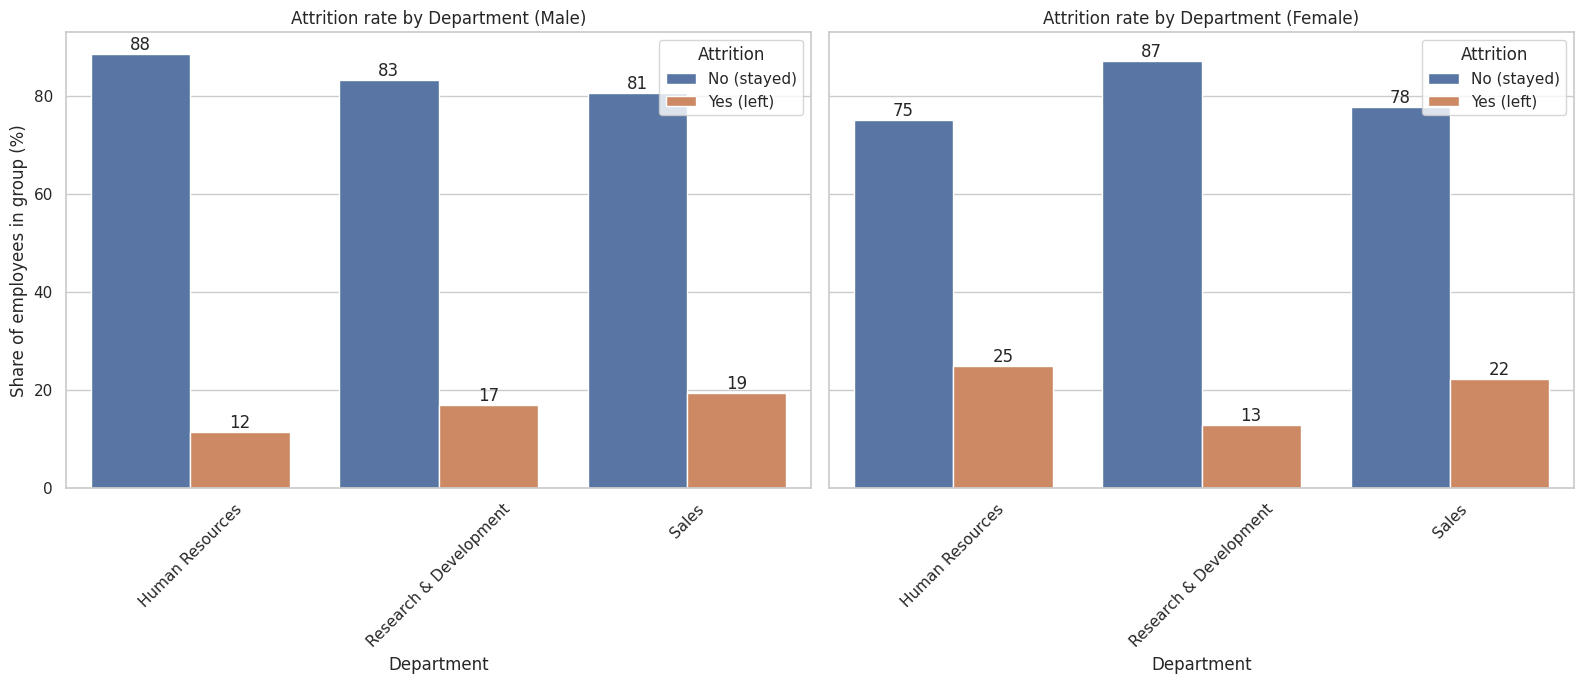

In [12]:
plot_attrition_rate_by_gender(employee_data, "Department")

**Insight 2: Department-by-gender differences look large but rest on very small groups and are not statistically significant.**

- **Finding.** The bars show the **attrition rate within each department-gender group**, not a share of all leavers. Men: Human Resources 12%, R&D 17%, Sales 19%. Women: Human Resources 25%, Sales 22%, R&D 13%.
- **Fact check.** The 25% for women in Human Resources is 3 leavers out of 12 labeled employees (computed from the raw data). In the chi-square test (Section 4.5.2), neither Gender (p = 0.66) nor Department (p = 0.10) shows a significant association with attrition at α = 0.05. This is consistent with meta-analytic evidence that demographic characteristics such as gender are weak predictors of voluntary turnover compared with job attitudes and work conditions (Rubenstein et al., 2018).
- **Caveats.** The largest gender gap, in Human Resources, rests on 12 women and 26 men (3 leavers in each group), so it does not support gender-specific conclusions. Gender is also a sensitive attribute.
- **Follow-up check.** Test the Gender × Department interaction (e.g. logistic regression with an interaction term) and report confidence intervals per cell.
- **Modeling/business implication.** No gender-specific retention policy should be based on this chart. Whether Gender may be used as a model input is a governance decision (`EXCLUDED_FEATURES`, Section 3.2).

#### 4.4.4 Attrition Rate by Work-Life Balance and Gender (Q2)

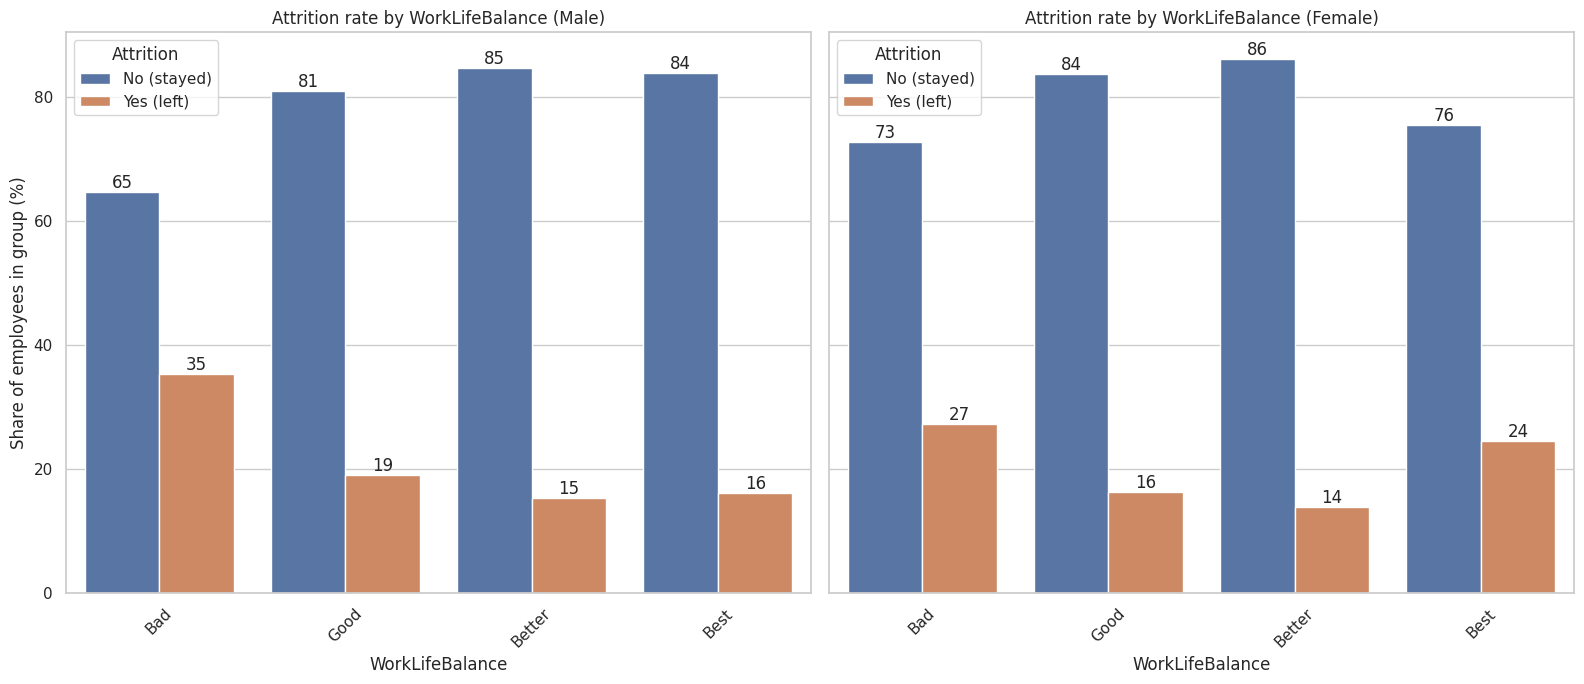

In [13]:
plot_attrition_rate_by_gender(
    employee_data, "WorkLifeBalance", ORDINAL_LABELS["WorkLifeBalance"]
)

**Insight 3: Employees who rate their work-life balance as "Bad" leave at roughly twice the average rate.**

- **Finding.** Attrition rate among men: Bad 35%, Good 19%, Better 15%, Best 16%. Among women: Bad 27%, Good 16%, Better 14%, Best 24%. The labels follow the official scale (1 = Bad, 2 = Good, 3 = Better, 4 = Best), so level 2 is already a positive answer.
- **Fact check.** Across both genders the "Bad" group's rate is 32.1% (vs. 16.9% overall). Work-life balance is significantly associated with attrition (chi-square p = 0.007, Section 4.5.2). Like Insight 2, the bars are within-group rates, not shares of leavers.
- **Caveats.** The "Bad" groups are small (34 men, 22 women; 18 leavers in total). The 24% rate for women rating "Best" is 11 leavers out of 45 and may be noise; it is not evidence that good work-life balance fails to retain women.
- **Follow-up check.** Compare the "Best" group's overtime and job-level mix with the other groups to see whether a third factor explains its uptick.
- **Modeling/business implication.** A "Bad" work-life-balance answer is a simple, actionable early-warning signal for HR. The feature is kept as an ordered numeric variable so the model can use its order.

#### 4.4.5 Job Satisfaction of Leavers vs. Stayers (Q2)

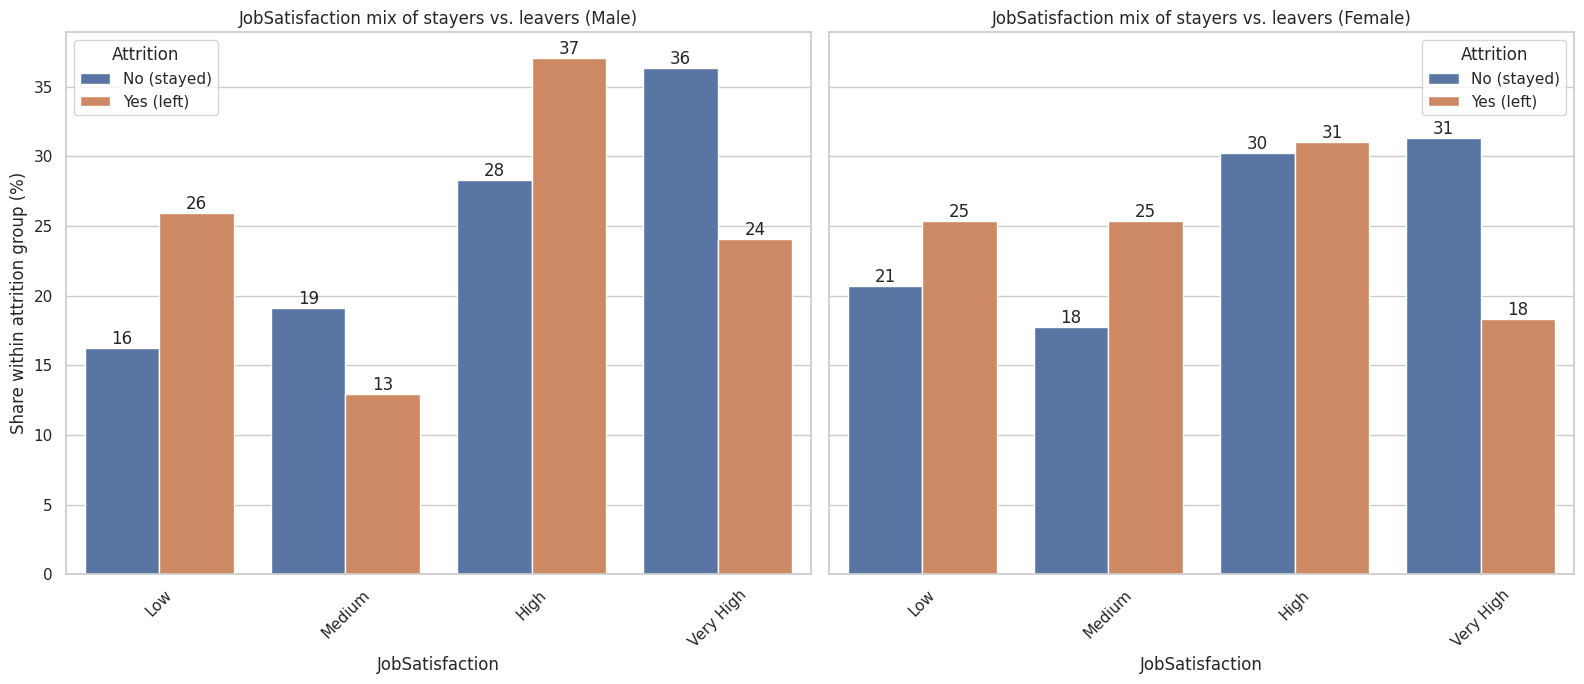

employees  attrition_rate
Gender JobSatisfaction                           
Female 1                       94           0.191
       2                       83           0.217
       3                      133           0.165
       4                      128           0.102
Male   1                      111           0.252
       2                      112           0.125
       3                      185           0.216
       4                      212           0.123

In [14]:
satisfaction_labels = ORDINAL_LABELS["JobSatisfaction"]
satisfaction_mix = (
    labeled_data.groupby([TARGET, "Gender"])["JobSatisfaction"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Percentage")
    .reset_index()
    .assign(
        JobSatisfaction=lambda d: d["JobSatisfaction"].map(satisfaction_labels),
        **{TARGET: lambda d: d[TARGET].map(ATTRITION_LABELS)},
    )
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, gender in zip(axes, ("Male", "Female"), strict=True):
    plot_bar(
        satisfaction_mix[satisfaction_mix["Gender"] == gender],
        "JobSatisfaction",
        "Percentage",
        hue=TARGET,
        order=list(satisfaction_labels.values()),
        hue_order=list(ATTRITION_LABELS.values()),
        title=f"JobSatisfaction mix of stayers vs. leavers ({gender})",
        xlabel="JobSatisfaction",
        ylabel="Share within attrition group (%)",
        ax=ax,
    )
fig.tight_layout()
plt.show()

# Attrition rate per satisfaction level: the figure needed to judge risk.
display(
    labeled_data.groupby(["Gender", "JobSatisfaction"])[TARGET]
    .agg(employees="size", attrition_rate="mean")
    .round(3)
)

**Insight 4: "High" satisfaction is the most common answer among leavers only because it is the most common answer overall; "Very High" satisfaction has the lowest attrition rate.**

- **Finding.** This chart shows a different quantity from Insights 2–3: within each outcome group, the percentage of employees at each satisfaction level. Among male leavers, 37% answered High, 26% Low, 24% Very High and 13% Medium; among female leavers, 31% High, 25% Low, 25% Medium and 18% Very High.
- **Fact check.** Attrition *rates* per level, shown in the table below the chart: men Low 25.2%, Medium 12.5%, High 21.6%, Very High 12.3%; women Low 19.1%, Medium 21.7%, High 16.5%, Very High 10.2%. Job satisfaction is significantly associated with attrition (chi-square p = 0.004, Section 4.5.2), in line with meta-analytic evidence that job attitudes are among the established antecedents of voluntary turnover (Rubenstein et al., 2018).
- **Caveats.** Reading the chart as "good job satisfaction is no guarantee of retention" would be a base-rate error: "High" dominates the leaver group because it is common, not because it is risky. The relationship is not strictly monotonic (e.g. women at "Medium" vs. "Low"), and group sizes are 83–212.
- **Follow-up check.** Model satisfaction jointly with overtime and job level to check whether the non-monotonic steps persist after adjustment.
- **Modeling/business implication.** The clearest signal is protective: employees at "Very High" satisfaction have the lowest rate for each gender (10.2% for women, 12.3% for men), about two-thirds of the overall 16.9%. Satisfaction is kept as an ordered numeric feature.

#### 4.4.6 Mean Monthly Income by Department and Gender (Q3)

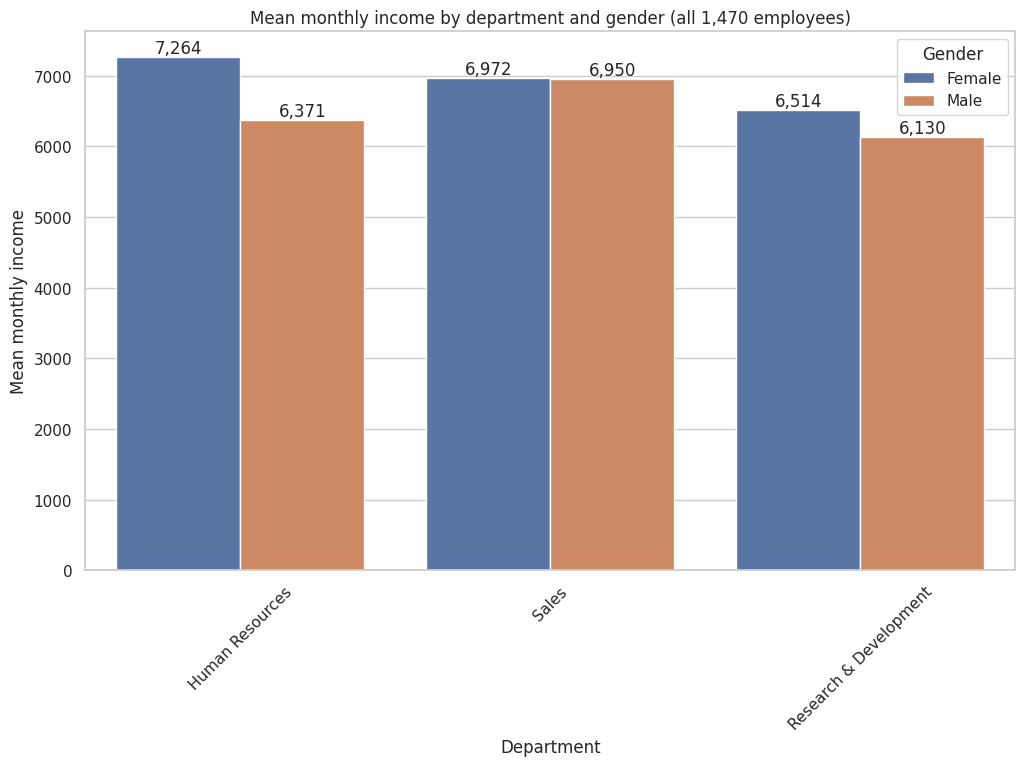

In [15]:
income_by_dept_gender = (
    employee_data.groupby(["Department", "Gender"])["MonthlyIncome"]
    .mean()
    .reset_index()
    .sort_values("MonthlyIncome", ascending=False)
)

plt.figure(figsize=(12, 7))
plot_bar(
    income_by_dept_gender,
    "Department",
    "MonthlyIncome",
    hue="Gender",
    title="Mean monthly income by department and gender (all 1,470 employees)",
    xlabel="Department",
    ylabel="Mean monthly income",
)
plt.show()

**Insight 5: Women's mean income is higher than or equal to men's in every department, but the raw comparison does not control for job level or role.**

- **Finding.** Mean monthly income for men: Sales 6,950, Human Resources 6,371, R&D 6,130. For women: Human Resources 7,264, Sales 6,972, R&D 6,514. The gap is largest in Human Resources (about 890) and negligible in Sales (22). Across all employees, the mean is 6,687 for women and 6,381 for men (medians 5,082 vs. 4,838; computed from the raw data).
- **Caveats.** This is an unadjusted comparison. Women in the data also hold a slightly higher average job level (2.12 vs. 2.03), and job level drives income strongly (Insight 9). Because the dataset is fictional, the chart says nothing about real-world pay equity.
- **Follow-up check.** Compare income by gender within the same JobLevel and JobRole.
- **Modeling/business implication.** No evidence here that pay differences by gender drive attrition; income itself is examined against attrition in Insights 6 and 8.

#### 4.4.7 Median Monthly Income of Stayers vs. Leavers by Department and Gender (Q3)

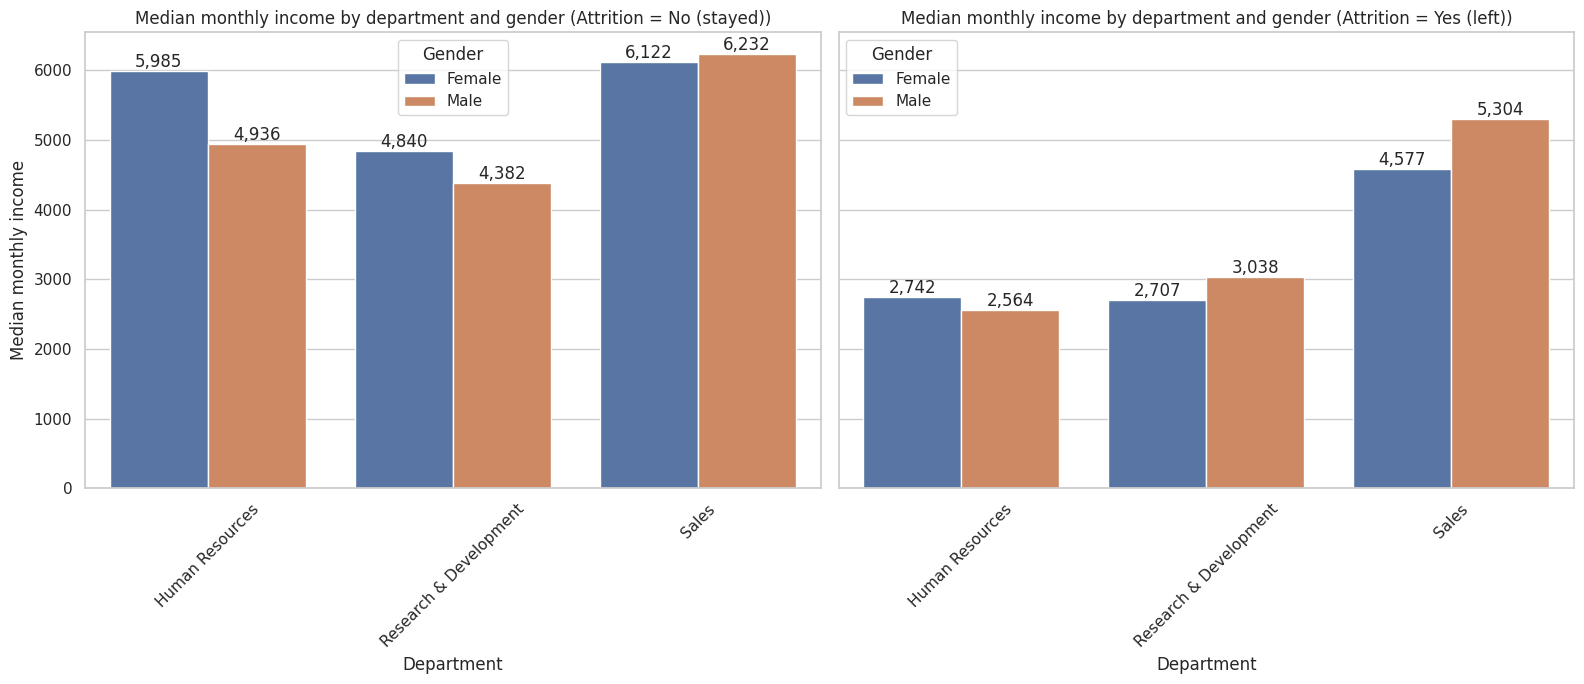

In [16]:
median_income = (
    labeled_data.groupby(["Department", TARGET, "Gender"])["MonthlyIncome"]
    .median()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, (code, label) in zip(axes, ATTRITION_LABELS.items(), strict=True):
    plot_bar(
        median_income[median_income[TARGET] == code],
        "Department",
        "MonthlyIncome",
        hue="Gender",
        hue_order=["Female", "Male"],
        title=f"Median monthly income by department and gender (Attrition = {label})",
        xlabel="Department",
        ylabel="Median monthly income",
        ax=ax,
    )
fig.tight_layout()
plt.show()

**Insight 6: In every department-gender group, leavers earned less than stayers.**

- **Finding.** The chart shows **medians**. Stayers: men in Sales 6,232 (highest for men), men in R&D 4,382 (lowest), women in R&D 4,840 (lowest for women). Leavers: men in Sales 5,304 and women in Sales 4,577 are the highest among leavers.
- **Fact check.** Comparing the two panels group by group (values from the raw data): Sales men 6,232 → 5,304; Sales women 6,122 → 4,577; R&D men 4,382 → 3,038; R&D women 4,840 → 2,707. Sales leavers earn the most among leavers only because Sales pays more overall; within Sales, leavers still earn less than stayers.
- **Caveats.** Human Resources leaver medians rest on 3 women and 3 men. Medians do not adjust for job level, which is lower among leavers.
- **Follow-up check.** Repeat the comparison within each JobLevel to separate a pay effect from a seniority effect.
- **Modeling/business implication.** Lower pay relative to colleagues in the same department is consistently associated with leaving, which supports keeping MonthlyIncome (and JobLevel) as model inputs.

#### 4.4.8 Median Monthly Income by Job Role (Q3)

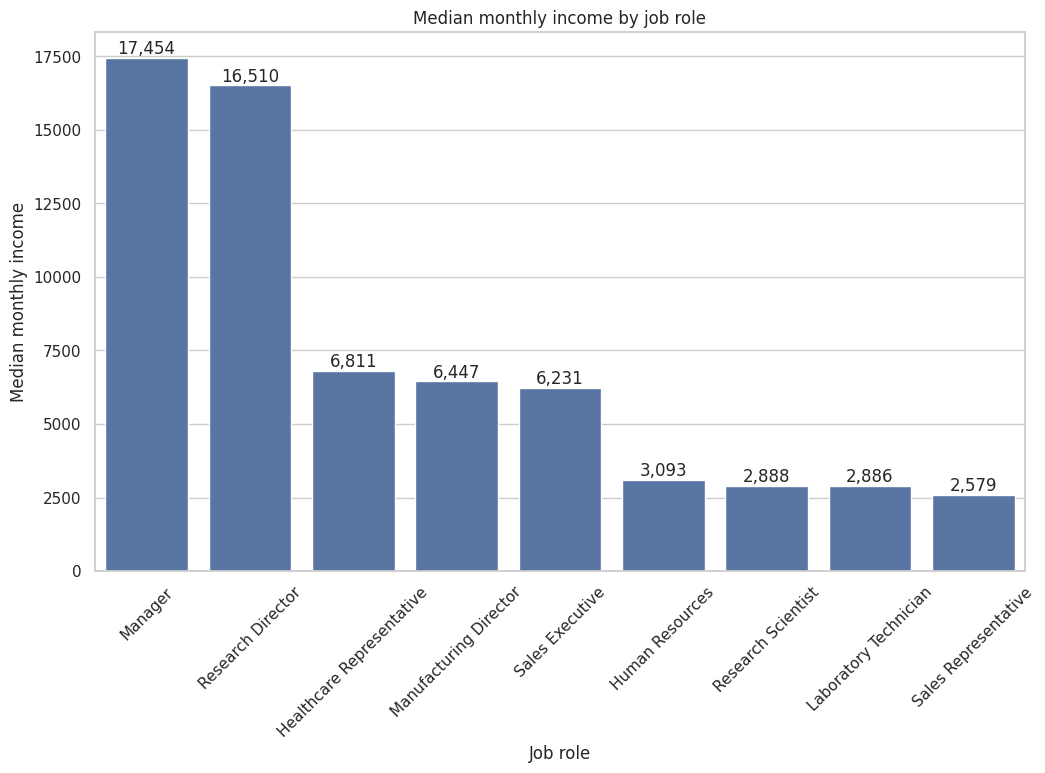

In [17]:
income_by_role = (
    employee_data.groupby("JobRole")["MonthlyIncome"]
    .median()
    .reset_index()
    .sort_values("MonthlyIncome", ascending=False)
)

plt.figure(figsize=(12, 7))
plot_bar(
    income_by_role,
    "JobRole",
    "MonthlyIncome",
    title="Median monthly income by job role",
    xlabel="Job role",
    ylabel="Median monthly income",
)
plt.show()

**Insight 7: Pay is strongly tiered by role; the four lowest-paid roles cluster around 2,600–3,100 per month.**

- **Finding.** Medians: Manager 17,454 and Research Director 16,510 are the only roles above 10,000, about 944 apart. Healthcare Representative (6,811), Manufacturing Director (6,447) and Sales Executive (6,231) form a middle tier. Sales Representative (2,579), Laboratory Technician (2,886), Research Scientist (2,888) and Human Resources (3,093) form the lowest tier.
- **Caveats.** Role and job level overlap heavily, so role-level pay differences largely reflect seniority.
- **Follow-up check.** Cross-tabulate JobRole with JobLevel and attrition rate.
- **Modeling/business implication.** JobRole is significantly associated with attrition (chi-square p < 0.001, Section 4.5.2), and the lowest-paid tier coincides with entry-level positions, where the attrition rate is 27.4% (JobLevel 1, computed from the raw data) vs. 5–15% at higher levels.

#### 4.4.9 Distribution of Monthly Income by Attrition Status (Q3)

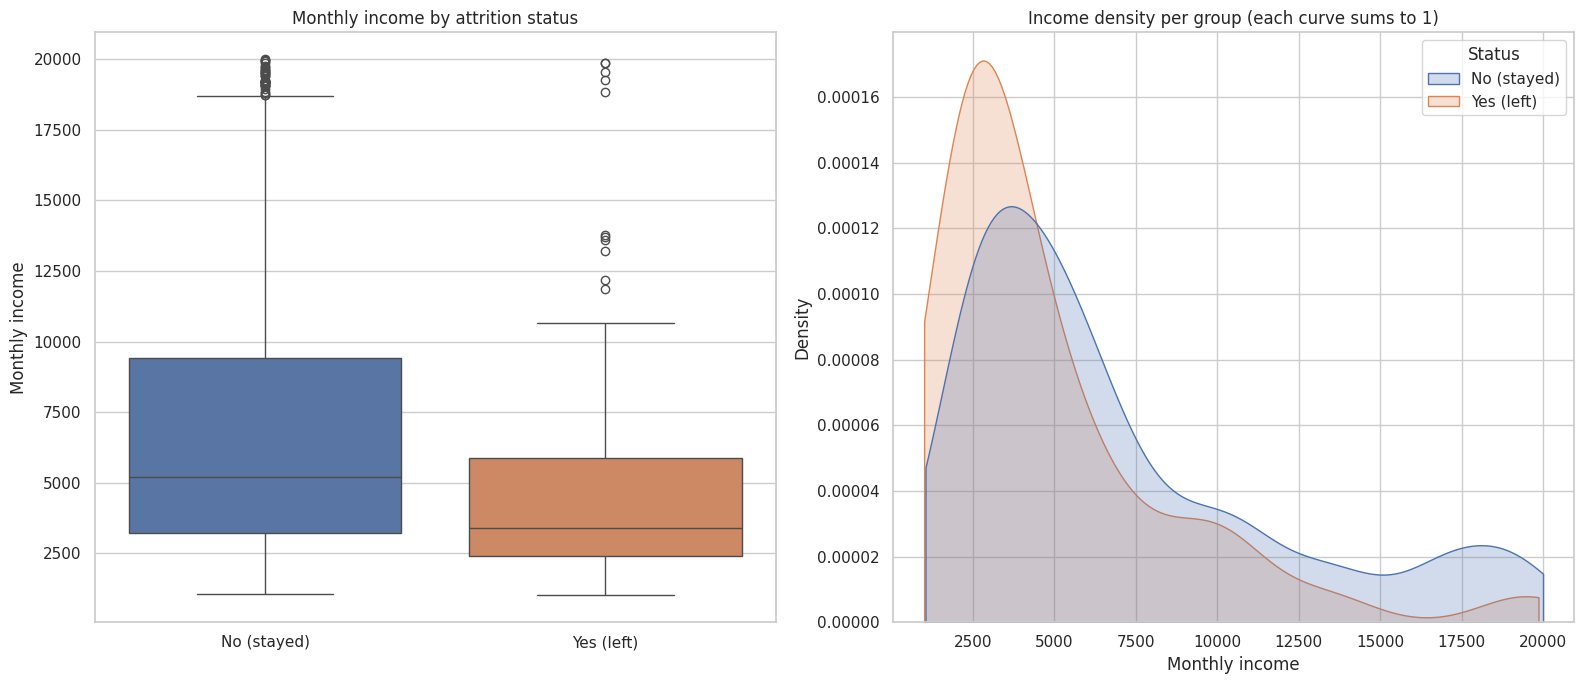

In [18]:
income_plot_data = labeled_data.assign(
    Status=labeled_data[TARGET].map(ATTRITION_LABELS)
)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.boxplot(
    data=income_plot_data,
    x="Status",
    y="MonthlyIncome",
    hue="Status",
    order=status_order,
    hue_order=status_order,
    legend=False,
    ax=axes[0],
)
axes[0].set(
    title="Monthly income by attrition status", xlabel="", ylabel="Monthly income"
)

# common_norm=False scales each curve to an area of 1, so the shapes are
# comparable even though there are about five times more stayers than leavers.
sns.kdeplot(
    data=income_plot_data,
    x="MonthlyIncome",
    hue="Status",
    hue_order=status_order,
    common_norm=False,
    fill=True,
    cut=0,
    ax=axes[1],
)
axes[1].set(
    title="Income density per group (each curve sums to 1)", xlabel="Monthly income"
)

fig.tight_layout()
plt.show()

**Insight 8: Leavers are concentrated at the low end of the pay scale; their median income is about one-third lower than that of stayers.**

- **Finding.** Median monthly income is about 3,400 for leavers vs. 5,200 for stayers; the middle 50% range is roughly 2,400–5,900 for leavers vs. 3,200–9,400 for stayers (exact values from the raw data: medians 3,388 vs. 5,210).
- **Fact check.** The leavers' upper whisker ends near 10,600, but several leavers are outliers between about 11,800 and 19,900, so high pay does not rule out leaving. A Welch t-test and a Mann-Whitney U test (Section 4.5.1) confirm the difference.
- **Caveats.** Each density curve is normalized to an area of 1, so the shapes are comparable despite the roughly 5:1 group sizes: the leavers' curve peaks near 2,900, the stayers' near 3,700 with a second bump around 18,000 (senior roles). Both charts use the same colors for the same group.
- **Follow-up check.** Plot attrition rate by income decile to see whether risk falls steadily or drops after a threshold.
- **Modeling/business implication.** Low pay is a strong, actionable risk signal, but it overlaps with job level and age; the model will use all three and importance must be read with that overlap in mind.

#### 4.4.10 Monthly Income vs. Total Working Years by Job Level (Q3)

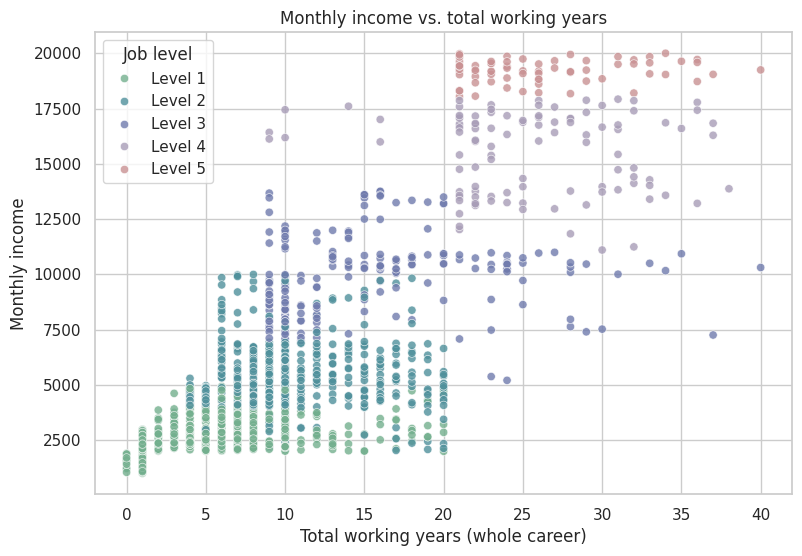

In [19]:
job_level_labels = ORDINAL_LABELS["JobLevel"]
scatter_data = employee_data.assign(
    JobLevel=employee_data["JobLevel"].map(job_level_labels)
)

plt.figure(figsize=(9, 6))
ax = sns.scatterplot(
    data=scatter_data,
    x="TotalWorkingYears",
    y="MonthlyIncome",
    hue="JobLevel",
    hue_order=list(job_level_labels.values()),
    palette=["#73AF8E", "#4F909B", "#707BAD", "#A89DB7", "#C99193"],
    alpha=0.8,
)
ax.set(
    title="Monthly income vs. total working years",
    xlabel="Total working years (whole career)",
    ylabel="Monthly income",
)
ax.legend(title="Job level")
plt.show()

**Insight 9: Income rises with career length, but job level is what moves employees between pay bands.**

- **Finding.** Income increases with total working years (Pearson r = 0.77, Section 4.4.11), and the points form horizontal bands by job level: each level occupies its own income range, with limited overlap.
- **Caveats.** `TotalWorkingYears` is the length of the employee's **whole career**, not time spent at this company (that is `YearsAtCompany`). The level names (Level 1–5) are neutral labels, because the data dictionary does not name the grades.
- **Modeling/business implication.** Promotion (job level) is the main route to higher pay. Combined with Insight 7, employees who stay at Level 1 are the population most exposed to attrition.

#### 4.4.11 Correlation between Numeric Features (Q4)

- MonthlyIncome & TotalWorkingYears: 0.7729
- YearsAtCompany & YearsWithCurrManager: 0.7692
- YearsAtCompany & YearsInCurrentRole: 0.7588
- YearsInCurrentRole & YearsWithCurrManager: 0.7144
- Age & TotalWorkingYears: 0.6804
- TotalWorkingYears & YearsAtCompany: 0.6281
- YearsAtCompany & YearsSinceLastPromotion: 0.6184


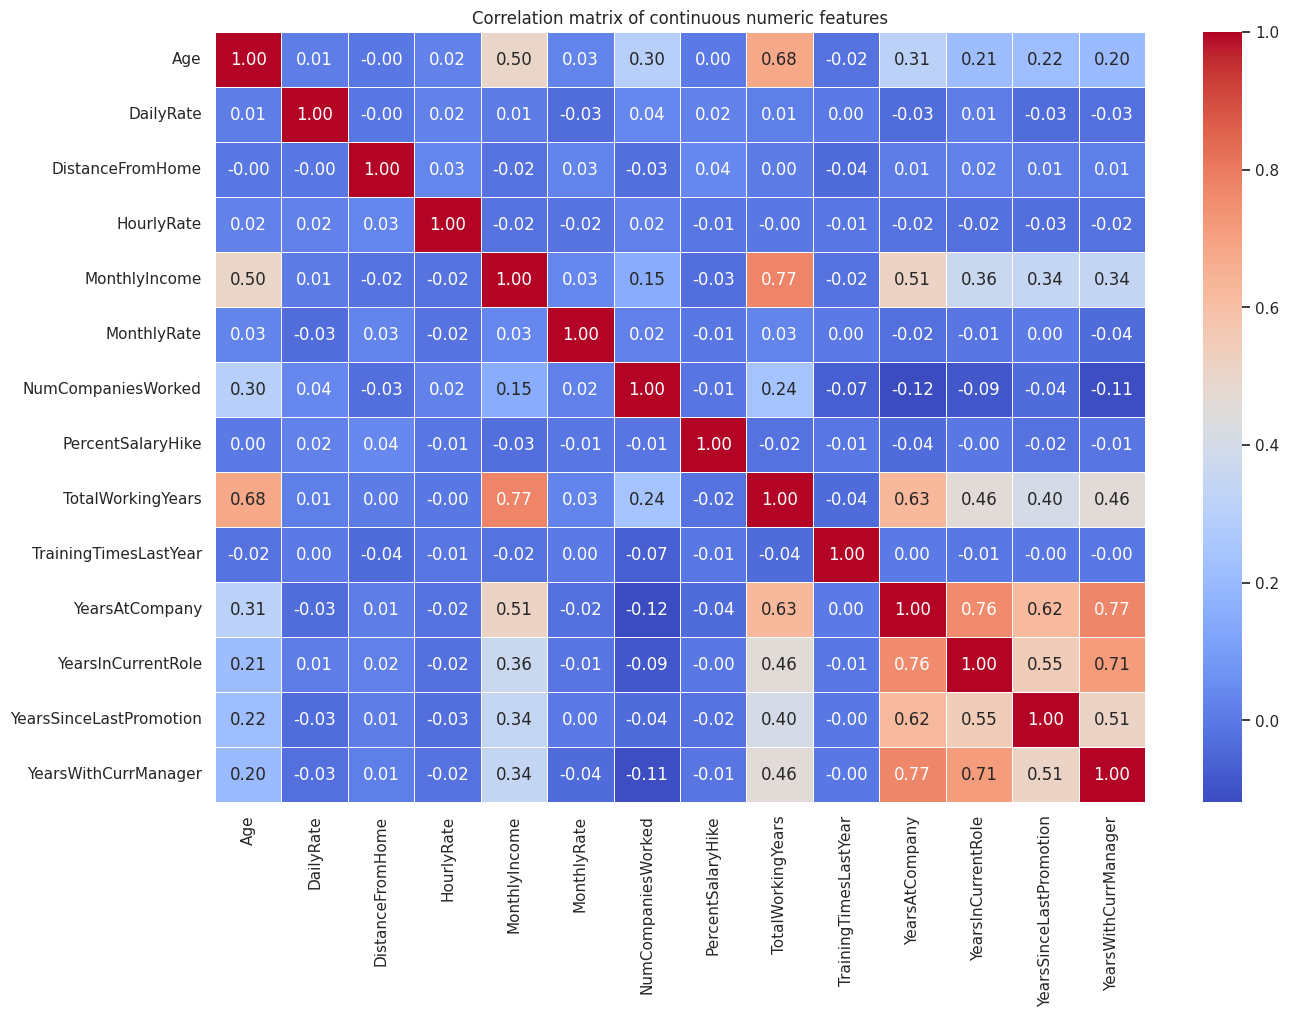

In [20]:
# Coded scales (<= 5 distinct values) are excluded: Pearson correlation
# assumes interval data.
continuous_cols = [
    col
    for col in employee_data.select_dtypes("number").columns
    if col != ID_COL and employee_data[col].nunique() > 5
]
corr_matrix = employee_data[continuous_cols].corr()

upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
strong_pairs = (
    upper_triangle.stack()
    .loc[lambda pairs: pairs.abs() >= CORR_THRESHOLD]
    .sort_values(ascending=False)
)
for (feature_a, feature_b), r in strong_pairs.items():
    print(f"- {feature_a} & {feature_b}: {r:.4f}")

plt.figure(figsize=(15, 10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation matrix of continuous numeric features")
plt.show()

**Insight 10: Seven pairs of features are strongly correlated (r ≥ 0.6), almost all of them measures of time.**

- **Finding.** MonthlyIncome & TotalWorkingYears (0.77), YearsWithCurrManager & YearsAtCompany (0.77), YearsAtCompany & YearsInCurrentRole (0.76), YearsWithCurrManager & YearsInCurrentRole (0.71), TotalWorkingYears & Age (0.68), YearsAtCompany & TotalWorkingYears (0.63) and YearsAtCompany & YearsSinceLastPromotion (0.62).
- **Caveats.** Correlation is not dependence on attrition, and these are Pearson coefficients on skewed variables (Section 4.4.12); rank correlations would be more robust. Coded scales such as JobLevel are excluded from the matrix even though JobLevel is closely tied to income (Insight 9).
- **Modeling/business implication.** Gradient Boosting predictions are not harmed by correlated inputs, so no feature is dropped. Interpretation is affected, though: importance is shared among correlated features, so a tenure feature that ranks low may still matter. The engineered features in Section 5.2 are built from these tenure columns.

#### 4.4.12 Skewness of Continuous Features (Q4)

In [21]:
skewness = employee_data[continuous_cols].skew()
skewed_features = (
    skewness[skewness.abs() > SKEW_LIMIT].sort_values(ascending=False).to_frame("Skew")
)
display(
    skewed_features.style.set_caption(f"Continuous features with |skew| > {SKEW_LIMIT}")
)

,Skew
YearsSinceLastPromotion,1.984290
YearsAtCompany,1.764529
MonthlyIncome,1.369817
TotalWorkingYears,1.117172
NumCompaniesWorked,1.026471
DistanceFromHome,0.958118
YearsInCurrentRole,0.917363
YearsWithCurrManager,0.833451
PercentSalaryHike,0.821128


**Insight 11: Nine continuous features are right-skewed, but no transformation is needed for the chosen model.**

- **Finding.** YearsSinceLastPromotion (1.98), YearsAtCompany (1.76), MonthlyIncome (1.37), TotalWorkingYears (1.12), NumCompaniesWorked (1.03), DistanceFromHome (0.96), YearsInCurrentRole (0.92), YearsWithCurrManager (0.83) and PercentSalaryHike (0.82) exceed |skew| = 0.75.
- **Caveats.** A log transform applied before feature engineering would also distort the engineered features in Section 5.2, for example turning a difference in years into a log-ratio.
- **Modeling/business implication.** Decision trees split on thresholds, so any order-preserving transformation (such as a log) leaves a Gradient Boosting model unchanged. The log transform and the standard scaling step are therefore removed, and all features stay in their original, interpretable units.

### 4.5 Statistical Association Tests (Descriptive)

These tests quantify whether the patterns seen in the EDA are larger than chance. They are run on the 1,058 employees with a known outcome and are used **descriptively**; the chi-square screen that selects features is repeated on the training split only (Section 5.6), so the test set does not influence feature selection.

#### 4.5.1 Numeric Features: Mann-Whitney U and Welch t-Tests

For every continuous numeric feature (the same columns as the correlation matrix in Section 4.4.11):

- **H0:** the feature is distributed the same way among leavers and stayers.
- **H1:** it differs.

The rank-based *Mann-Whitney U test* is the main test because most of these features are skewed (Section 4.4.12); the *Welch t-test* (comparison of means without assuming equal variances) is reported alongside. The *rank-biserial correlation* expresses the effect size from −1 to +1: **positive means leavers tend to have higher values**, negative means lower; about 0.1 is small, 0.3 medium and 0.5 large. Because 14 features are tested at once, p-values are also adjusted with the *Benjamini-Hochberg* procedure, which limits the expected share of false discoveries to 5%.

In [22]:
def compare_numeric_groups(data: pd.DataFrame, columns: Sequence[str]) -> pd.DataFrame:
    """Compare numeric features between leavers and stayers.

    Args:
        data: Employees with a known outcome; must contain ``TARGET``.
        columns: Numeric columns to compare.

    Returns:
        One row per feature with group medians, Mann-Whitney U and Welch
        p-values, the Benjamini-Hochberg adjusted Mann-Whitney p-value and
        the rank-biserial correlation (positive = leavers higher), sorted by
        the strength of the effect.
    """
    rows = []
    for col in columns:
        stayed = data.loc[data[TARGET] == 0, col]
        left = data.loc[data[TARGET] == 1, col]
        mann_whitney = stats.mannwhitneyu(left, stayed, alternative="two-sided")
        welch = stats.ttest_ind(left, stayed, equal_var=False)
        rows.append(
            {
                "Feature": col,
                "Median_stayed": stayed.median(),
                "Median_left": left.median(),
                "Rank_biserial": 2 * mann_whitney.statistic / (len(left) * len(stayed))
                - 1,
                "MWU_p_value": mann_whitney.pvalue,
                "Welch_p_value": welch.pvalue,
            }
        )
    results = pd.DataFrame(rows)
    results["MWU_p_adjusted"] = stats.false_discovery_control(results["MWU_p_value"])
    results["Significant"] = results["MWU_p_adjusted"] < ALPHA
    return results.sort_values(
        "Rank_biserial",
        key=lambda effect: effect.abs(),
        ascending=False,
        ignore_index=True,
    )


numeric_test_results = compare_numeric_groups(labeled_data, continuous_cols)
display(numeric_test_results.round(4))

,Feature,Median_stayed,Median_left,Rank_biserial,MWU_p_value,Welch_p_value,MWU_p_adjusted,Significant
0,TotalWorkingYears,10.0,7.0,-0.3209,0.0000,0.0000,0.0000,True
1,MonthlyIncome,5210.0,3388.0,-0.3066,0.0000,0.0000,0.0000,True
2,YearsAtCompany,6.0,3.0,-0.2911,0.0000,0.0000,0.0000,True
3,Age,36.0,31.0,-0.2796,0.0000,0.0000,0.0000,True
4,YearsInCurrentRole,3.0,2.0,-0.2677,0.0000,0.0000,0.0000,True
5,YearsWithCurrManager,3.0,2.0,-0.2605,0.0000,0.0000,0.0000,True
6,DistanceFromHome,7.0,8.0,0.1167,0.0135,0.0163,0.0269,True
7,DailyRate,829.0,699.0,-0.0804,0.0898,0.0911,0.1397,False
8,YearsSinceLastPromotion,1.0,1.0,-0.0771,0.0898,0.2946,0.1397,False
9,TrainingTimesLastYear,3.0,2.0,-0.0633,0.1618,0.1295,0.2265,False


**Insight 12: Leavers are younger, earlier in their careers and paid less; seven of 14 numeric features differ significantly.**

- **Finding.** The cell compares all 14 continuous features, ordered by the size of the effect. Seven differ significantly after the Benjamini-Hochberg adjustment:

  | Feature | Median stayed | Median left | Rank-biserial | Adjusted p |
  |---|---|---|---|---|
  | TotalWorkingYears | 10 | 7 | −0.32 | < 0.001 |
  | MonthlyIncome | 5,210 | 3,388 | −0.31 | < 0.001 |
  | YearsAtCompany | 6 | 3 | −0.29 | < 0.001 |
  | Age | 36 | 31 | −0.28 | < 0.001 |
  | YearsInCurrentRole | 3 | 2 | −0.27 | < 0.001 |
  | YearsWithCurrManager | 3 | 2 | −0.26 | < 0.001 |
  | DistanceFromHome | 7 | 8 | +0.12 | 0.027 |

  Not significant after adjustment: DailyRate, YearsSinceLastPromotion, TrainingTimesLastYear, MonthlyRate, NumCompaniesWorked, HourlyRate and PercentSalaryHike (adjusted p ≥ 0.14). The Welch t-test agrees for every significant feature (p < 0.02).
- **Caveats.** The six strongest effects are medium-sized and measure overlapping things: age, career length, tenure and income rise together (Insight 10), so they likely reflect one underlying "early-career" profile rather than six independent causes. The distance effect is small. None of these tests shows causation.
- **Modeling/business implication.** H0 is rejected for seven features. Early-career, lower-paid employees with short tenure form the highest-risk profile, consistent with the Level 1 finding (Insight 7). Notably, the size of the last salary increase (PercentSalaryHike) and time since the last promotion show no association, which argues against across-the-board raise or promotion-timing policies as the main retention lever.

#### 4.5.2 Categorical Features: Chi-Square Test of Independence

For each categorical or coded feature, the chi-square test checks whether the attrition rate differs across its categories (**H0:** the feature and attrition are independent). *Cramér's V* (0 = no association, 1 = perfect association) shows how strong a significant association is; with 1,058 employees, even weak associations can reach significance.

In [23]:
def chi_square_screen(data: pd.DataFrame, columns: Sequence[str]) -> pd.DataFrame:
    """Run a chi-square test of independence between each column and the target.

    Args:
        data: Employees with a known outcome; must contain ``TARGET``.
        columns: Categorical or coded columns to test.

    Returns:
        One row per column with the chi-square statistic, p-value, Cramer's V
        and whether the association is significant at ``ALPHA``.
    """
    rows = []
    for col in columns:
        observed = pd.crosstab(data[TARGET], data[col])
        result = stats.chi2_contingency(observed)
        min_dim = min(observed.shape) - 1
        rows.append(
            {
                "Variable": col,
                "Chi_Statistic": result.statistic,
                "P_value": result.pvalue,
                "Cramers_V": np.sqrt(
                    result.statistic / (observed.to_numpy().sum() * min_dim)
                ),
                "Significant": result.pvalue < ALPHA,
            }
        )
    return pd.DataFrame(rows).sort_values("P_value", ignore_index=True)


chi_square_results = chi_square_screen(labeled_data, NOMINAL_COLS + ORDINAL_COLS)
display(chi_square_results)

not_significant = chi_square_results.loc[~chi_square_results["Significant"], "Variable"]
print(
    f"No significant association at alpha = {ALPHA} "
    f"(absence of evidence, not proof of independence): {not_significant.tolist()}"
)

,Variable,Chi_Statistic,P_value,Cramers_V,Significant
0,OverTime,67.763459,1.843342e-16,0.253078,True
1,JobRole,66.393971,2.556695e-11,0.250508,True
2,JobLevel,53.520364,6.631672e-11,0.224914,True
3,StockOptionLevel,47.850308,2.291539e-10,0.212667,True
4,MaritalStatus,37.621652,6.769585e-09,0.188572,True
5,JobInvolvement,29.103478,2.130062e-06,0.165855,True
6,EnvironmentSatisfaction,21.880082,6.908816e-05,0.143808,True
7,BusinessTravel,13.403348,1.228853e-03,0.112555,True
8,JobSatisfaction,13.163605,4.295832e-03,0.111544,True
9,WorkLifeBalance,12.106043,7.028592e-03,0.106969,True


No significant association at alpha = 0.05 (absence of evidence, not proof of independence): ['EducationField', 'RelationshipSatisfaction', 'Department', 'Education', 'Gender', 'PerformanceRating']


**Insight 13: Overtime, job role, job level, stock options and marital status are the factors most strongly associated with attrition; six factors show no significant association.**

- **Finding.** 10 of 16 tested factors are significant at α = 0.05. Ranked by p-value: OverTime (χ² = 67.8), JobRole (66.4), JobLevel (53.5), StockOptionLevel (47.9), MaritalStatus (37.6), JobInvolvement (29.1), EnvironmentSatisfaction (21.9), BusinessTravel (13.4), JobSatisfaction (13.2) and WorkLifeBalance (12.1). Not significant: Department (p = 0.10), Education (0.28), EducationField (0.08), Gender (0.66), PerformanceRating (0.89) and RelationshipSatisfaction (0.09).
- **Fact check.** In the raw data, employees working overtime leave at 31.9% vs. 10.8% for those who do not; single employees at 26.7% vs. 13.4% (married) and 9.5% (divorced).
- **Caveats.** A p-value above 0.05 means no evidence of association was found, not proof of independence. With 16 tests, about one false positive is expected at α = 0.05. Because these results use all labeled employees, they are descriptive only; the screen that drives feature selection is repeated on the training split (Section 5.6).
- **Modeling/business implication.** The training-split screen is enabled (`DROP_CHI2_NOT_SIGNIFICANT = True`) and removes the same six features (Section 5.6). Gradient Boosting would tolerate uninformative inputs, so the gains are a simpler model and Gender no longer being a model input. OverTime becomes the rule-based benchmark the model must beat (criterion D2).

### 4.6 EDA Summary

| Question | Answer |
|---|---|
| Q1 — size and spread of attrition | 16.9% of employees with a known outcome left; Sales has the highest rate (20.7%). Department and gender differences are not statistically significant. |
| Q2 — work-life balance and satisfaction | "Bad" work-life balance doubles the rate (32%); "Very High" job satisfaction has the lowest rate (10.2–12.3% vs. 16.9% overall). Both are significant but moderate signals. |
| Q3 — pay | Leavers earn about one-third less (median 3,388 vs. 5,210) in every department; pay is tied to job level, and Level 1 has a 27% attrition rate. |
| All numeric features (Section 4.5.1) | Leavers are younger and have shorter careers, tenure and time in role (medium effects); salary hike, promotion timing and the rate columns show no association. |
| Q4 — redundancy and skew | Tenure features are strongly inter-correlated; nine features are skewed. Neither requires treatment for Gradient Boosting, but both affect how importance is interpreted. |

The strongest single factor is **overtime** (31.9% vs. 10.8%), followed by job role/level, stock options and marital status.

### 4.7 From EDA to Data Preparation

| EDA finding | Preparation decision | Section |
|---|---|---|
| `EmployeeCount`, `Over18`, `StandardHours` are constant; `EmployeeId` is an identifier (Section 4.3) | Drop constant columns; keep `EmployeeId` as the index (not a feature) so risk scores can be traced back | 5.1 |
| Tenure features are related and career stagnation is plausible (Insights 9–10) | Engineer `MaxYearsSinceChange`, `ExperienceOutsideCompany`, `TrainingsPerYearAtCompany` from **raw** values | 5.2 |
| 412 employees have no outcome (Section 4.3) | Keep them as a separate scoring set instead of deleting them | 5.3 |
| Imbalanced target, 16.9% leavers (Insight 1) | Stratified 85/15 split and stratified 10-fold CV; recall-weighted threshold | 5.5, 5.7, 6.6 |
| Six categorical features show no significant association (Insight 13) | Repeat the chi-square screen on the training split only and drop the non-significant features | 5.6 |
| Skewed features; trees are invariant to monotonic transforms (Insight 11) | No log transform, no scaling | 5.7 |
| Ordered scales carry order information (Section 4.2) | Keep ordinal columns numeric; one-hot encode only nominal columns, fitted on training folds | 5.7 |
| Gender, MaritalStatus and Age are sensitive (Insight 2) | Expose `EXCLUDED_FEATURES` toggle for a fairness-aware variant | 3.2, 5.5 |

## 5. Data Preparation

Preparation follows four leakage-safe phases. Steps in **phase A** use only values from the same row (or remove constant columns), so they can safely run before the split. Everything that *learns* from data (encoding, optional feature screening, hyperparameters, decision threshold) is fitted on the training split only.

| CRISP-DM task | Phase | Section |
|---|---|---|
| Select data (drop constant and ID columns, optional exclusions) | A, B | 5.1, 5.5 |
| Clean data (missing labels → separate scoring set) | A | 5.3 |
| Construct data (engineered features) | A | 5.2 |
| Integrate data | — | single source, not needed |
| Format data (export for the Streamlit dashboard; one-hot encoding inside the pipeline) | A, C | 5.4, 5.7 |
| Generate test design (stratified split, stratified CV) | B, D | 5.5, 5.7 |

Not applied, by design: a log transform and feature scaling (no effect on tree models; Insight 11), a separate validation set (cross-validation is used instead, which keeps more data for training), and encoding outside the model pipeline (the encoder is fitted inside each training fold instead).

### 5.1 Phase A — Drop Uninformative Columns

In [24]:
constant_cols = [
    col
    for col in employee_data.columns
    if employee_data[col].nunique(dropna=False) <= 1
]

# EmployeeId becomes the index: it identifies people in the exported risk
# scores but must never be used as a model feature.
employee_df = employee_data.drop(columns=constant_cols).set_index(ID_COL)

print("Columns without variance:", constant_cols)
employee_df.shape

Columns without variance: ['EmployeeCount', 'Over18', 'StandardHours']


(1470, 31)

### 5.2 Phase A — Feature Engineering

Three features describe career dynamics that the raw columns only capture indirectly. Each is computed from the same employee's row, on the original (untransformed) values:

- **MaxYearsSinceChange** — the longest period without a change in role, promotion or manager; a proxy for career stagnation.
- **ExperienceOutsideCompany** — career years spent at previous employers (`TotalWorkingYears − YearsAtCompany`).
- **TrainingsPerYearAtCompany** — trainings attended last year divided by years at the company (minimum 1). Note: the numerator covers only the last year, so this is a training-intensity ratio, not a lifetime training frequency.

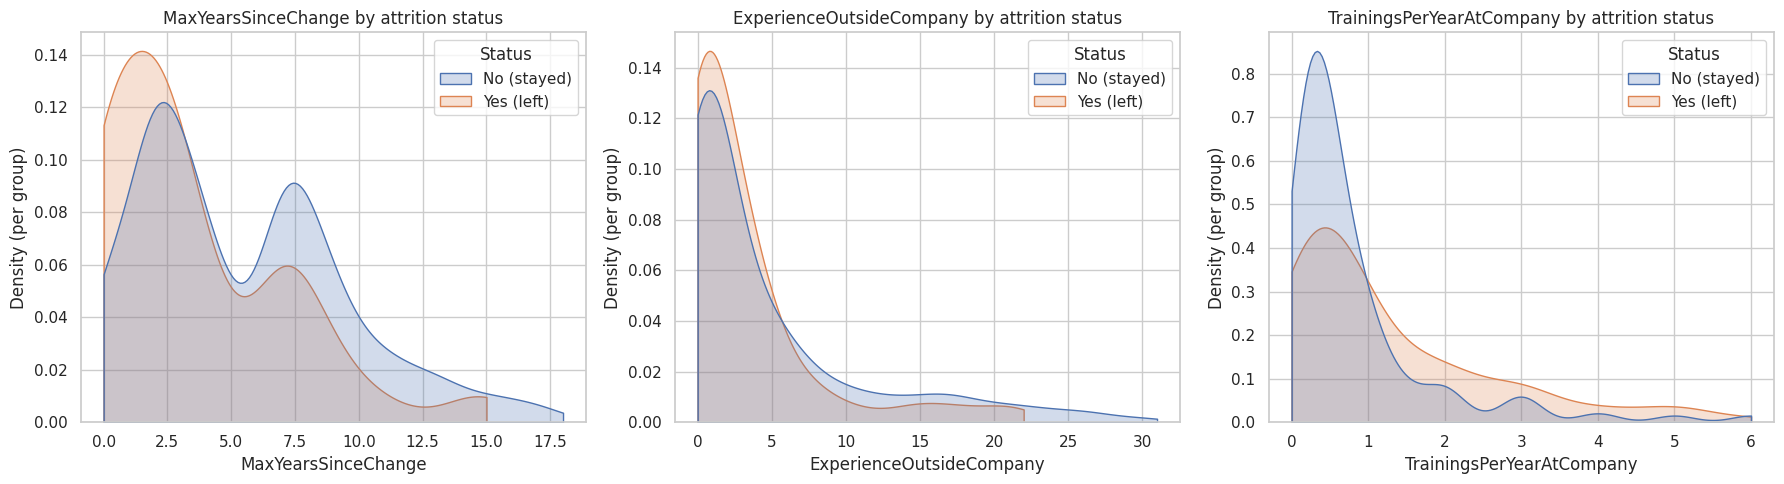

,count,mean,std,min,25%,50%,75%,max
MaxYearsSinceChange,1470.0,5.064626,3.991896,0.0,2.00,4.0,8.0,18.0
ExperienceOutsideCompany,1470.0,4.271429,6.179783,0.0,0.00,2.0,5.0,33.0
TrainingsPerYearAtCompany,1470.0,0.884039,1.079432,0.0,0.25,0.5,1.0,6.0


In [25]:
def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add career-dynamics features computed row by row from raw values.

    Because every value comes from the same employee's row, these features
    can be created before the train/test split without leaking information.

    Args:
        df: Employee data with the original tenure and training columns.

    Returns:
        A copy of ``df`` with the three columns listed in ``ENGINEERED_COLS``.
    """
    return df.assign(
        MaxYearsSinceChange=df[
            ["YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]
        ].max(axis=1),
        ExperienceOutsideCompany=df["TotalWorkingYears"] - df["YearsAtCompany"],
        # Employees in their first year (YearsAtCompany == 0) are divided by 1,
        # which reproduces the original fallback without a row-wise apply().
        TrainingsPerYearAtCompany=df["TrainingTimesLastYear"]
        / df["YearsAtCompany"].clip(lower=1),
    )


employee_df = add_engineered_features(employee_df)

engineered_plot_data = employee_df.dropna(subset=[TARGET]).assign(
    Status=lambda d: d[TARGET].map(ATTRITION_LABELS)
)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature in zip(axes, ENGINEERED_COLS, strict=True):
    sns.kdeplot(
        data=engineered_plot_data,
        x=feature,
        hue="Status",
        hue_order=status_order,
        common_norm=False,
        fill=True,
        cut=0,
        ax=ax,
    )
    ax.set(title=f"{feature} by attrition status", ylabel="Density (per group)")
fig.tight_layout()
plt.show()

display(employee_df[ENGINEERED_COLS].describe().T)

**Insight 14: The engineered features mostly re-express short tenure; leavers are not "stuck" longer than stayers.**

- **Finding.** Leavers concentrate at short `MaxYearsSinceChange` values (density peak near 1.5 years), while stayers show a second peak around 7.5 years and a longer tail. `ExperienceOutsideCompany` looks similar for both groups, with leavers slightly more concentrated below 3 years. `TrainingsPerYearAtCompany` has a heavier right tail for leavers. Across all employees the medians are 4 years, 2 years and 0.5 trainings per year.
- **Caveats.** Each feature is tied to tenure: `TrainingsPerYearAtCompany` divides by years at the company, so it is high for newcomers, and `MaxYearsSinceChange` cannot exceed tenure. The career-stagnation hypothesis behind `MaxYearsSinceChange` is therefore not supported: leavers are newer, not stalled.
- **Modeling/business implication.** In the permutation importance (Section 7.5), only `TrainingsPerYearAtCompany` reaches the top 15 (12th, with an error bar close to zero); the other two do not. The three features add little beyond the raw tenure columns; iteration 2 removes them without any loss in cross-validated average precision (Section 7.9.1).

### 5.3 Phase A — Separate Employees with and without a Known Outcome

The 412 rows with an empty `Attrition` value cannot be used for training or testing, but they are exactly the employees whose risk HR wants to know. They are kept as a separate **scoring set** (Section 8.2) and, using the outcomes in IBM's original file, as an **external validation set** (Section 8.3).

In [26]:
has_label = employee_df[TARGET].notna()
labeled_df = employee_df[has_label].astype({TARGET: int})
unlabeled_df = employee_df[~has_label].drop(columns=TARGET)

print(
    f"Labeled employees (train/test): {len(labeled_df):,} "
    f"| leavers: {labeled_df[TARGET].mean():.1%}"
)
print(f"Unlabeled employees (to be scored): {len(unlabeled_df):,}")

Labeled employees (train/test): 1,058 | leavers: 16.9%
Unlabeled employees (to be scored): 412


### 5.4 Phase A — Export for the Streamlit Dashboard

The Streamlit app (Section 8.5) needs every employee, in original units, with a readable status: `Yes` (left), `No` (stayed) or `Unknown` (no recorded outcome). The engineered features are included so the dashboard and the model describe employees in the same terms.

In [27]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

app_data = employee_df.assign(
    AttritionStatus=employee_df[TARGET].map({0: "No", 1: "Yes"}).fillna("Unknown")
).drop(columns=TARGET)
app_data.reset_index().to_csv(DASHBOARD_CSV_PATH, index=False)

print(f"Saved {len(app_data):,} rows to {DASHBOARD_CSV_PATH.relative_to(PROJECT_ROOT)}")
print(app_data["AttritionStatus"].value_counts().to_dict())

Saved 1,470 rows to data/processed/employee.csv
{'No': 879, 'Unknown': 412, 'Yes': 179}


### 5.5 Phase B — Test Design: Stratified Train/Test Split

85% of the labeled employees (899) are used for training and model selection, and 15% (159 employees, 27 of them leavers) are locked away as a **test set** that is used exactly once, in Section 7. *Stratification* keeps the share of leavers identical in both parts (16.9% and 17.0% in the output below), which matters with only about 180 leavers. Features listed in `EXCLUDED_FEATURES` are removed here; none are excluded in this run.

In [28]:
feature_cols = [
    col for col in labeled_df.columns if col != TARGET and col not in EXCLUDED_FEATURES
]
X = labeled_df[feature_cols]
y = labeled_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Features: {len(feature_cols)} | excluded: {list(EXCLUDED_FEATURES) or 'none'}")
for name, target in (("Train", y_train), ("Test", y_test)):
    print(f"{name:<5} {len(target):>4} rows | leavers: {target.mean():.1%}")

Features: 33 | excluded: none
Train  899 rows | leavers: 16.9%
Test   159 rows | leavers: 17.0%


### 5.6 Phase C — Chi-Square Feature Screening on the Training Split

With `DROP_CHI2_NOT_SIGNIFICANT = True`, the chi-square screen from Section 4.5.2 is repeated **on the training split only**, and features without a significant association are removed from both splits. Running the screen on all labeled data would let the test set influence feature selection.

**Result.** The screen removes EducationField, Department, RelationshipSatisfaction, Gender, Education and PerformanceRating, the same six features as the descriptive test on all labeled data (Insight 13). 27 of the 33 candidate features remain; after one-hot encoding they become 40 model columns (Section 5.7).

In [29]:
if DROP_CHI2_NOT_SIGNIFICANT:
    screened = [col for col in NOMINAL_COLS + ORDINAL_COLS if col in X_train.columns]
    train_screen = chi_square_screen(X_train.assign(**{TARGET: y_train}), screened)
    dropped_features = train_screen.loc[
        ~train_screen["Significant"], "Variable"
    ].tolist()
    X_train = X_train.drop(columns=dropped_features)
    X_test = X_test.drop(columns=dropped_features)
    feature_cols = X_train.columns.tolist()
    print(f"Dropped after train-only screening: {dropped_features}")
else:
    print(f"All {len(feature_cols)} features kept (DROP_CHI2_NOT_SIGNIFICANT = False).")

Dropped after train-only screening: ['EducationField', 'Department', 'RelationshipSatisfaction', 'Gender', 'Education', 'PerformanceRating']


### 5.7 Phases C & D — Preprocessing Pipeline and Cross-Validation Folds

*One-hot encoding* turns each nominal category into a 0/1 column. It is placed **inside** a scikit-learn `Pipeline`, so in every cross-validation fold it is fitted on that fold's training part only, and the saved model can later score raw employee records directly. Ordinal and numeric columns pass through unchanged. Categories that never appeared during training are encoded as all zeros instead of raising an error.

*Stratified 10-fold cross-validation* splits the training set into ten parts with the same share of leavers; each model is trained ten times, each time validated on a different part. All model and threshold choices in Section 6 are based on these folds; the test set stays untouched.

In [30]:
def build_preprocessor(columns: Sequence[str]) -> ColumnTransformer:
    """Create the encoder that turns raw employee records into model inputs.

    Args:
        columns: Feature columns that will be passed to the pipeline.

    Returns:
        A transformer that one-hot encodes nominal columns and passes all
        other columns through unchanged.
    """
    nominal = [col for col in NOMINAL_COLS if col in columns]
    return ColumnTransformer(
        [
            (
                "nominal",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                nominal,
            )
        ],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )


cv_folds = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
build_preprocessor(feature_cols).fit(X_train).get_feature_names_out().size

40

## 6. Modeling

### 6.1 Candidate Algorithm and Search Space

**Gradient Boosting** builds an ensemble of small decision trees one after another; each new tree corrects the errors of the trees before it (Friedman, 2001). It handles mixed feature types and non-linear interactions (e.g. overtime combined with low pay), needs no scaling, and is a strong default for tabular data of this size. scikit-learn's `GradientBoostingClassifier` is used, so the whole workflow needs only one machine-learning library.

**Optuna** searches the hyperparameters with a *Tree-structured Parzen Estimator* (TPE): after a few random trials, it concentrates new trials in regions that scored well (Akiba et al., 2019). This is more sample-efficient than random or grid search. Each of the **100 trials** is scored by 10-fold cross-validated **average precision** on the training split, the metric best suited to a rare positive class (Saito & Rehmsmeier, 2015).

| Hyperparameter | Range | Effect |
|---|---|---|
| `n_estimators` | 100–600 (step 50) | Number of trees |
| `learning_rate` | 0.005–0.3 (log scale) | Contribution of each tree; smaller values need more trees |
| `max_depth` | 2–6 | Complexity of each tree / order of interactions |
| `min_samples_leaf` | 1–50 (log scale) | Minimum employees per leaf; larger values regularize |
| `subsample` | 0.6–1.0 | Share of rows per tree; < 1 adds randomness that reduces overfitting |
| `max_features` | sqrt, log2, all | Features considered per split |

### 6.2 Training and Cross-Validation Utilities

In [31]:
def build_pipeline(columns: Sequence[str], **gb_params: Any) -> Pipeline:
    """Combine preprocessing and a Gradient Boosting classifier in one pipeline.

    Args:
        columns: Feature columns expected by the pipeline.
        **gb_params: Hyperparameters for ``GradientBoostingClassifier``.

    Returns:
        An unfitted pipeline that accepts raw employee records.
    """
    return Pipeline(
        [
            ("preprocess", build_preprocessor(columns)),
            (
                "model",
                GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params),
            ),
        ]
    )


def cross_validate_pipeline(
    pipeline: Pipeline, X: pd.DataFrame, y: pd.Series, cv: StratifiedKFold
) -> dict[str, float]:
    """Return mean and standard deviation of each ``CV_SCORING`` metric.

    Args:
        pipeline: Unfitted pipeline to evaluate.
        X: Training features.
        y: Training target.
        cv: Cross-validation splitter.

    Returns:
        Mapping such as ``{"average_precision": 0.52,
        "average_precision_std": 0.04, ...}``.
    """
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=CV_SCORING, n_jobs=-1)
    summary: dict[str, float] = {}
    for metric in CV_SCORING:
        fold_scores = scores[f"test_{metric}"]
        summary[metric] = float(fold_scores.mean())
        summary[f"{metric}_std"] = float(fold_scores.std())
    return summary


def save_json(record: dict[str, Any] | list[dict[str, Any]], path: Path) -> None:
    """Write a flat JSON record (or list of flat records) to disk.

    Args:
        record: Dictionary with scalar values, or a list of such dictionaries.
        path: Destination file; parent folders are created if needed.
    """
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(record, indent=2, default=str), encoding="utf-8")

### 6.3 Baseline Model (Default Hyperparameters)

The baseline is a Gradient Boosting model with scikit-learn's default settings. Tuning is only worthwhile if it beats this baseline in cross-validation.

In [32]:
baseline_cv = cross_validate_pipeline(
    build_pipeline(feature_cols), X_train, y_train, cv_folds
)
pd.Series(baseline_cv, name=f"Baseline GB ({CV_FOLDS}-fold CV)").round(4).to_frame()

,Baseline GB (10-fold CV)
average_precision,0.5330
average_precision_std,0.0848
roc_auc,0.7983
roc_auc_std,0.0727


With default settings, Gradient Boosting already reaches a cross-validated average precision of **0.533** (± 0.085 across folds) and an ROC AUC of **0.798** (± 0.073), roughly three times the 0.17 that a random ranking would achieve.

### 6.4 Hyperparameter Tuning with Optuna (100 Trials)

Each trial samples one hyperparameter combination, cross-validates it on the training split and reports the mean average precision. The sampler is seeded for reproducibility. Results are saved as two **flat JSON** files (one level of keys, no nesting), so they can be read by any tool or loaded straight into a table:

- `artifacts/tuning/optuna_best_params.json` — the best trial: its CV scores, its hyperparameters (prefixed `param_`) and run metadata.
- `artifacts/tuning/optuna_tuning_results.json` — one flat record per trial (the full tuning history).

In [33]:
def suggest_gb_params(trial: optuna.Trial) -> dict[str, Any]:
    """Sample one Gradient Boosting configuration from ``GB_SEARCH_SPACE``.

    Args:
        trial: The Optuna trial that records the sampled values.

    Returns:
        Hyperparameters for ``GradientBoostingClassifier``.
    """
    space = GB_SEARCH_SPACE
    low, high, step = space["n_estimators"]
    return {
        "n_estimators": trial.suggest_int("n_estimators", low, high, step=step),
        "learning_rate": trial.suggest_float(
            "learning_rate", *space["learning_rate"], log=True
        ),
        "max_depth": trial.suggest_int("max_depth", *space["max_depth"]),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", *space["min_samples_leaf"], log=True
        ),
        "subsample": trial.suggest_float("subsample", *space["subsample"]),
        "max_features": trial.suggest_categorical(
            "max_features", space["max_features"]
        ),
    }


def objective(trial: optuna.Trial) -> float:
    """Cross-validate one sampled configuration and return ``OPTUNA_METRIC``.

    All CV scores are stored as trial attributes so the saved history also
    contains ROC AUC, not only the optimized metric.

    Args:
        trial: The Optuna trial being evaluated.

    Returns:
        Mean cross-validated ``OPTUNA_METRIC`` on the training split.
    """
    pipeline = build_pipeline(feature_cols, **suggest_gb_params(trial))
    scores = cross_validate_pipeline(pipeline, X_train, y_train, cv_folds)
    for metric, value in scores.items():
        trial.set_user_attr(metric, value)
    return scores[OPTUNA_METRIC]


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    study_name="attrition_gradient_boosting",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=N_TRIALS)

best_trial = study.best_trial
best_params = dict(best_trial.params)
print(f"Best trial #{best_trial.number}: CV {OPTUNA_METRIC} = {best_trial.value:.4f}")
print(f"Best hyperparameters: {best_params}")

Best trial #66: CV average_precision = 0.6036
Best hyperparameters: {'n_estimators': 200, 'learning_rate': 0.028221272063006633, 'max_depth': 4, 'min_samples_leaf': 28, 'subsample': 0.8695728632510606, 'max_features': 'sqrt'}


In [34]:
run_metadata = {
    "study_name": study.study_name,
    "objective_metric": OPTUNA_METRIC,
    "direction": "maximize",
    "n_trials": len(study.trials),
    "cv_folds": CV_FOLDS,
    "train_rows": len(X_train),
    "random_state": RANDOM_STATE,
    "sampler": type(study.sampler).__name__,
    "optuna_version": optuna.__version__,
    "sklearn_version": sklearn.__version__,
    "created_at_utc": datetime.now(UTC).isoformat(timespec="seconds"),
}
best_record = {
    "best_trial_number": best_trial.number,
    **{f"cv_{metric}": value for metric, value in best_trial.user_attrs.items()},
    **{f"param_{name}": value for name, value in best_params.items()},
    **run_metadata,
}
trial_records = [
    {
        "trial_number": trial.number,
        "state": trial.state.name,
        "value": trial.value,
        "duration_seconds": trial.duration.total_seconds() if trial.duration else None,
        **{f"cv_{metric}": value for metric, value in trial.user_attrs.items()},
        **{f"param_{name}": value for name, value in trial.params.items()},
    }
    for trial in study.trials
]

save_json(best_record, TUNING_BEST_PATH)
save_json(trial_records, TUNING_RESULTS_PATH)
print(f"Saved {TUNING_BEST_PATH.name} and {TUNING_RESULTS_PATH.name}")
pd.Series(best_record).to_frame("value")

Saved optuna_best_params.json and optuna_tuning_results.json


,value
best_trial_number,66
cv_average_precision,0.603579
cv_average_precision_std,0.104712
cv_roc_auc,0.814757
cv_roc_auc_std,0.075639
param_n_estimators,200
param_learning_rate,0.028221
param_max_depth,4
param_min_samples_leaf,28
param_subsample,0.869573


### 6.5 Tuning Diagnostics

The optimization history shows whether the search converged: if the best-so-far line is still rising near the last trial, more trials could help; a flat line means further tuning is unlikely to pay off. The second chart shows which hyperparameter values scored well.

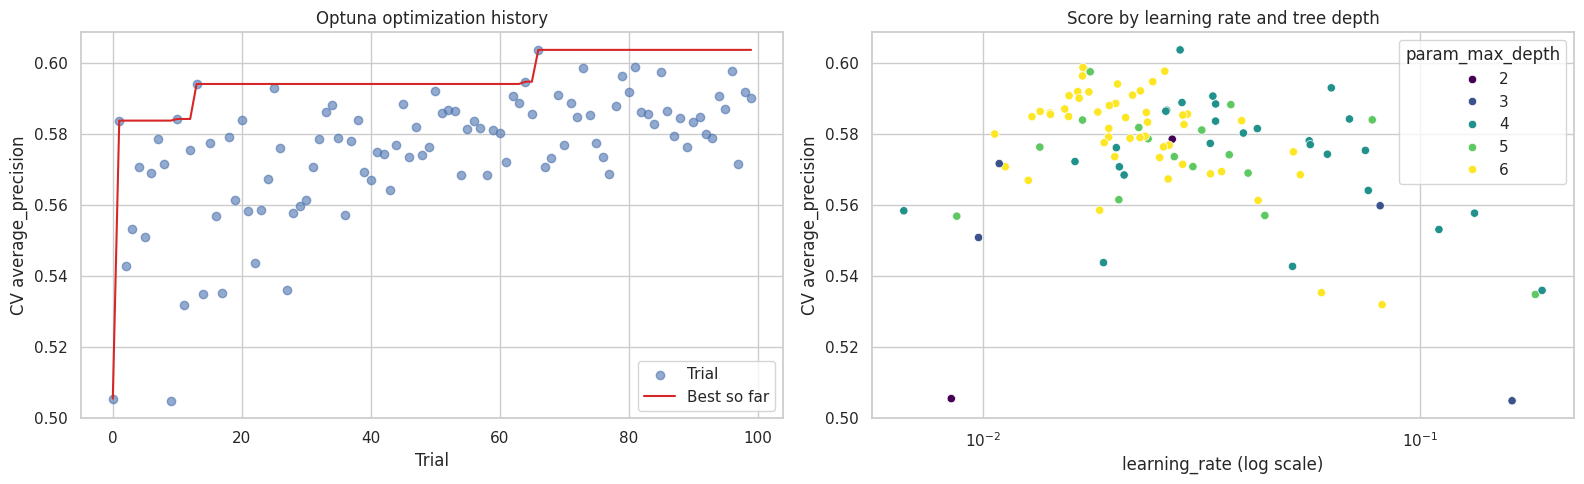

In [35]:
trials_df = pd.DataFrame(trial_records).query("state == 'COMPLETE'")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].scatter(trials_df["trial_number"], trials_df["value"], alpha=0.6, label="Trial")
axes[0].plot(
    trials_df["trial_number"],
    trials_df["value"].cummax(),
    color="tab:red",
    label="Best so far",
)
axes[0].set(
    title="Optuna optimization history", xlabel="Trial", ylabel=f"CV {OPTUNA_METRIC}"
)
axes[0].legend()

sns.scatterplot(
    data=trials_df,
    x="param_learning_rate",
    y="value",
    hue="param_max_depth",
    palette="viridis",
    ax=axes[1],
)
axes[1].set(
    xscale="log",
    title="Score by learning rate and tree depth",
    xlabel="learning_rate (log scale)",
    ylabel=f"CV {OPTUNA_METRIC}",
)
fig.tight_layout()
plt.show()

**Insight 15: The search converged; the best configuration uses moderate learning rates, depth-4 trees and large leaves.**

- **Finding.** The best-so-far average precision rises from 0.584 (trial 1) to 0.594 (trial 13) and 0.604 (trial 66), then stays flat for the remaining 33 trials. The best trial uses 200 trees, a learning rate of 0.028, depth 4, at least 28 employees per leaf, 87% of rows per tree and the square root of the features per split (output of Section 6.4). Most high-scoring trials have learning rates between about 0.01 and 0.04 with depths of 4–6; learning rates above 0.1 score lower.
- **Caveats.** The gain after trial 13 (+0.010) is about one-tenth of the fold-to-fold standard deviation (0.105), so the last 86 trials refined the result only marginally. The best of 100 trials is also selected on the same folds and is therefore slightly optimistic.
- **Modeling/business implication.** The search budget is sufficient; large leaves (28 employees) and row subsampling act as regularization, which suits a dataset with about 150 leavers in the training split.

### 6.6 Model and Decision-Threshold Selection

**Model selection.** The tuned configuration is kept only if it beats the default baseline on cross-validated average precision; otherwise the default settings are used. (The best of 100 trials is slightly optimistic, because it was selected on the same folds; the untouched test set in Section 7 gives the unbiased estimate.)

**Decision threshold.** A classifier outputs a probability; the *threshold* turns it into a yes/no flag. The default of 0.5 is rarely right for a rare class. `TunedThresholdClassifierCV` searches the threshold that maximizes the **F2 score** across the same 10 training folds, so missing a leaver is penalized more than a false alarm, without looking at the test set.

In [36]:
selection = pd.DataFrame(
    {
        "Baseline (default)": baseline_cv,
        "Optuna-tuned": {
            k: v for k, v in best_trial.user_attrs.items() if k in baseline_cv
        },
    }
).T
display(selection.round(4))

use_tuned = (
    selection.loc["Optuna-tuned", OPTUNA_METRIC]
    > selection.loc["Baseline (default)", OPTUNA_METRIC]
)
selected_params = best_params if use_tuned else {}
selected_name = "Optuna-tuned" if use_tuned else "Baseline (default)"
selected_cv = selection.loc[selected_name]
print(f"Selected model: {selected_name}")

f_beta_scorer = make_scorer(fbeta_score, beta=F_BETA)
final_model = TunedThresholdClassifierCV(
    build_pipeline(feature_cols, **selected_params),
    scoring=f_beta_scorer,
    cv=cv_folds,
    random_state=RANDOM_STATE,
).fit(X_train, y_train)
print(
    f"Decision threshold maximizing CV F{F_BETA:g}: {final_model.best_threshold_:.3f}"
)

,average_precision,average_precision_std,roc_auc,roc_auc_std
Baseline (default),0.5330,0.0848,0.7983,0.0727
Optuna-tuned,0.6036,0.1047,0.8148,0.0756


Selected model: Optuna-tuned
Decision threshold maximizing CV F2: 0.086


The tuned configuration improves the cross-validated average precision from 0.533 to **0.604** and the ROC AUC from 0.798 to **0.815**, so it is selected. The F2-optimal threshold is **0.086**: an employee is flagged once the model gives a probability of leaving of about 9% or more. Such a low threshold is expected when recall counts twice as much as precision and only one in six employees leaves; the price is a long list of flagged employees (Section 7.2).

## 7. Evaluation

### 7.1 Setup

The test set (15% of labeled employees: 159 employees, 27 of them leavers) is used **once**, here, after every modelling choice has been fixed. Metrics are defined in Section 2.4. Two benchmarks put the numbers in context:

- **Majority class** — predicts that nobody leaves. It shows how misleading accuracy is on imbalanced data.
- **Business rule** — flags every employee who works overtime, the strongest single factor in the EDA (Insight 13). This is what HR could do without a model.

### 7.2 Test-Set Predictions and Benchmarks

In [37]:
def classification_summary(
    y_true: pd.Series, y_pred: np.ndarray, y_score: np.ndarray | None = None
) -> dict[str, float]:
    """Compute the evaluation metrics from Section 2.4 for one set of predictions.

    Args:
        y_true: Actual outcomes (1 = left).
        y_pred: Predicted 0/1 flags.
        y_score: Predicted probabilities of leaving; ranking metrics
            (ROC AUC, average precision) are only computed when given.

    Returns:
        Metric name to value.
    """
    summary = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        f"f{F_BETA:g}": fbeta_score(y_true, y_pred, beta=F_BETA, zero_division=0),
        "flagged_share": float(np.mean(y_pred)),
    }
    if y_score is not None:
        summary |= {
            "roc_auc": roc_auc_score(y_true, y_score),
            "average_precision": average_precision_score(y_true, y_score),
        }
    return summary


y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = final_model.predict(X_test)
overtime_rule = (
    (labeled_df.loc[X_test.index, "OverTime"] == "Yes").astype(int).to_numpy()
)

test_results = pd.DataFrame(
    {
        "Majority class (nobody leaves)": classification_summary(
            y_test, np.zeros(len(y_test), dtype=int)
        ),
        "Rule: OverTime == 'Yes'": classification_summary(y_test, overtime_rule),
        f"Gradient Boosting ({selected_name})": classification_summary(
            y_test, y_test_pred, y_test_proba
        ),
    }
).T
test_results.round(3)

,accuracy,precision,recall,f1,f2,flagged_share,roc_auc,average_precision
Majority class (nobody leaves),0.830,0.000,0.000,0.000,0.000,0.000,NaN,NaN
Rule: OverTime == 'Yes',0.748,0.356,0.593,0.444,0.523,0.283,NaN,NaN
Gradient Boosting (Optuna-tuned),0.667,0.324,0.889,0.475,0.659,0.465,0.869,0.653


**Insight 16: The model catches 24 of the 27 test-set leavers, eight more than the overtime rule, at similar precision.**

- **Finding.** At its F2 threshold, Gradient Boosting reaches recall **0.889** (24 of 27 leavers), precision 0.324, F2 **0.659**, ROC AUC **0.869** and average precision **0.653**, about 3.8 times the test-set share of leavers (0.17). The overtime rule catches 16 of 27 leavers (recall 0.593) with precision 0.356 and F2 0.523. The majority-class benchmark reaches 83.0% accuracy while catching nobody.
- **Caveats.** The model flags 46.5% of the test employees (74 of 159) versus 28.3% for the overtime rule, so its higher recall is bought with a longer list; its accuracy (66.7%) is lower than the majority benchmark, which is the expected trade-off when recall is prioritized. With 27 leavers, one leaver more or less moves recall by 3.7 percentage points.
- **Modeling/business implication.** For the same precision (about one true leaver per three flags), the model finds half again as many leavers as a single-rule filter. If HR capacity is limited, working down the ranked list (Section 7.4) gives higher precision than using the flag alone.

### 7.3 Performance against the Data-Mining Criteria

In [38]:
def assess_criteria(
    model: pd.Series, rule: pd.Series, cv_roc_auc: float, prevalence: float
) -> pd.DataFrame:
    """Check one model's test metrics against criteria D1-D4 (Section 2.4).

    Args:
        model: Test metrics of the model (output of ``classification_summary``).
        rule: Test metrics of the OverTime rule on the same employees.
        cv_roc_auc: Cross-validated ROC AUC of the same configuration.
        prevalence: Share of leavers in the evaluated set.

    Returns:
        One row per criterion with its value and whether it is met.
    """
    f_beta_name = f"f{F_BETA:g}"
    gap = abs(cv_roc_auc - model["roc_auc"])
    return pd.DataFrame(
        [
            (
                "D1",
                f"Test ROC AUC >= {MIN_TEST_ROC_AUC}",
                model["roc_auc"],
                model["roc_auc"] >= MIN_TEST_ROC_AUC,
            ),
            (
                "D2",
                f"Test F2 > OverTime rule ({rule[f_beta_name]:.3f})",
                model[f_beta_name],
                model[f_beta_name] > rule[f_beta_name],
            ),
            (
                "D3",
                f"Average precision >= {AP_LIFT_TARGET:g} x prevalence "
                f"({AP_LIFT_TARGET * prevalence:.3f})",
                model["average_precision"],
                model["average_precision"] >= AP_LIFT_TARGET * prevalence,
            ),
            (
                "D4",
                f"|CV ROC AUC ({cv_roc_auc:.3f}) - test ROC AUC| <= {MAX_CV_TEST_GAP}",
                gap,
                gap <= MAX_CV_TEST_GAP,
            ),
        ],
        columns=["ID", "Criterion", "Value", "Met"],
    )


gb_test = test_results.iloc[-1]
rule_test = test_results.loc["Rule: OverTime == 'Yes'"]
criteria_results = assess_criteria(
    gb_test, rule_test, selected_cv["roc_auc"], y_test.mean()
)
criteria_results.round(3)

,ID,Criterion,Value,Met
0,D1,Test ROC AUC >= 0.75,0.869,True
1,D2,Test F2 > OverTime rule (0.523),0.659,True
2,D3,Average precision >= 2 x prevalence (0.340),0.653,True
3,D4,|CV ROC AUC (0.815) - test ROC AUC| <= 0.05,0.054,False


D1, D2 and D3 are met by a clear margin: ROC AUC 0.869 against 0.75, F2 0.659 against 0.523, and average precision 0.653 against 0.340. **D4 is narrowly missed:** the test ROC AUC (0.869) is 0.054 *higher* than the cross-validated value (0.815). A test score above the CV score is not a sign of overfitting; with 27 test leavers and a fold-to-fold standard deviation of 0.076, it most likely reflects a favorable test sample. The CV estimate (about 0.81–0.82) is the more realistic expectation for new data, and the external validation in Section 8.3 provides a second, independent check.

### 7.4 Diagnostics: Confusion Matrix, ROC and Precision-Recall Curves

The *confusion matrix* counts correct and incorrect flags at the selected threshold. The *ROC curve* and the *precision-recall curve* show the trade-offs across all thresholds; the dashed line in the precision-recall plot is the share of leavers, i.e. what a random ranking would achieve.

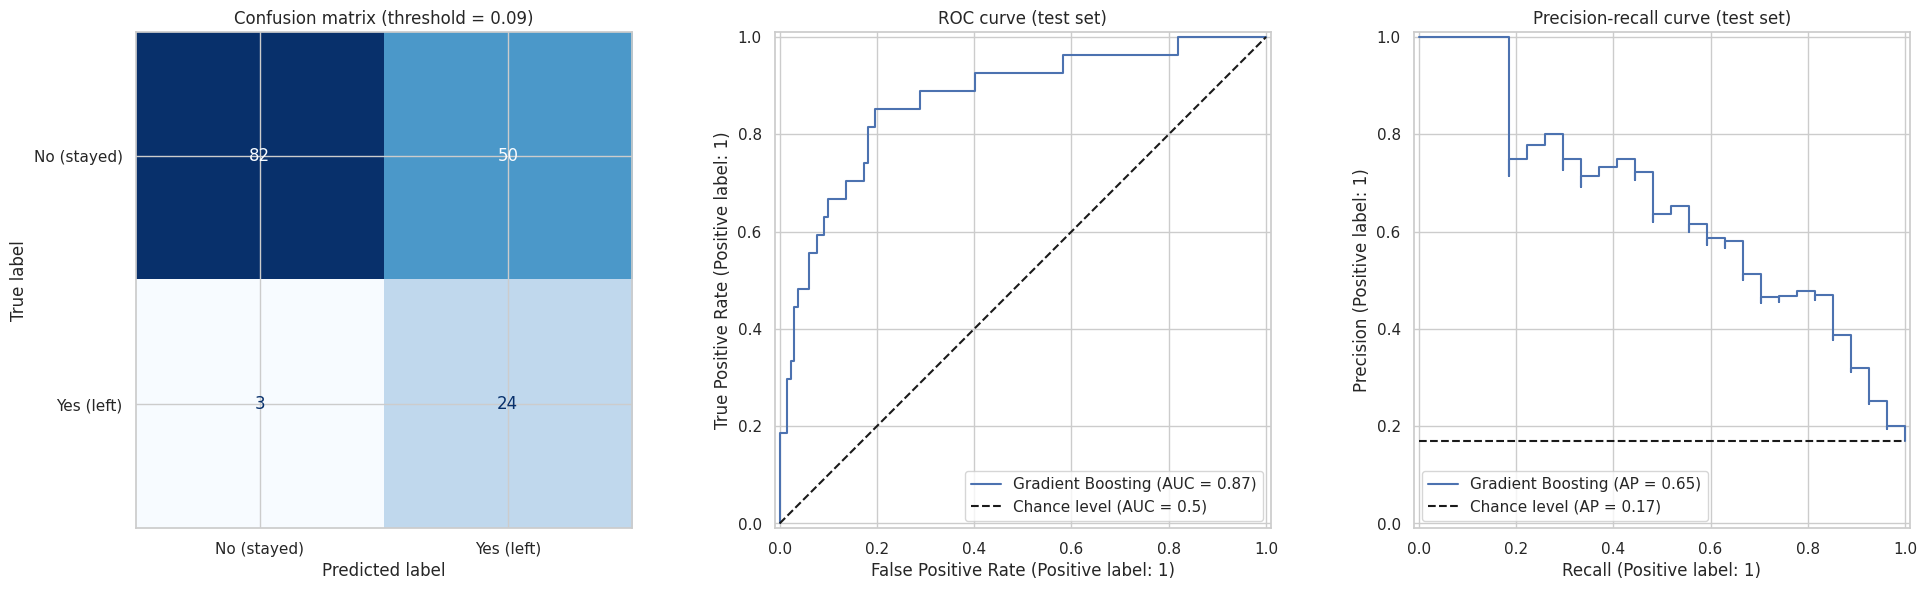

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=list(ATTRITION_LABELS.values()),
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title(f"Confusion matrix (threshold = {final_model.best_threshold_:.2f})")

RocCurveDisplay.from_predictions(
    y_test, y_test_proba, name="Gradient Boosting", plot_chance_level=True, ax=axes[1]
)
axes[1].set_title("ROC curve (test set)")

PrecisionRecallDisplay.from_predictions(
    y_test, y_test_proba, name="Gradient Boosting", plot_chance_level=True, ax=axes[2]
)
axes[2].set_title("Precision-recall curve (test set)")

fig.tight_layout()
plt.show()

At the threshold of 0.09, the confusion matrix shows 24 leavers caught and 3 missed, while 50 of the 132 stayers are flagged as well (82 correctly cleared). The ROC curve (AUC 0.87) rises steeply at the start: the highest-ranked employees are mostly true leavers. The precision-recall curve confirms this: precision stays around 0.7–0.8 while the first 20–45% of leavers are found, and falls below 0.5 only beyond about 70% recall. A short list of the highest-ranked employees is therefore far more precise than the full flag list.

### 7.5 Which Features Drive the Predictions? (Permutation Importance)

*Permutation importance* shuffles one feature at a time in the test set and measures how much average precision drops; a large drop means the model relies on that feature. Unlike impurity-based importance, it is measured on unseen data and works on the original feature names (e.g. `OverTime`, not `OverTime_Yes`).

Importance shows **how much** the model uses a feature, not **in which direction** or whether the relationship is causal. Direction is read from the EDA (e.g. overtime raises the attrition rate; "Very High" job satisfaction lowers it). Correlated features (Insight 10) share importance, so a low score does not prove a feature is irrelevant.

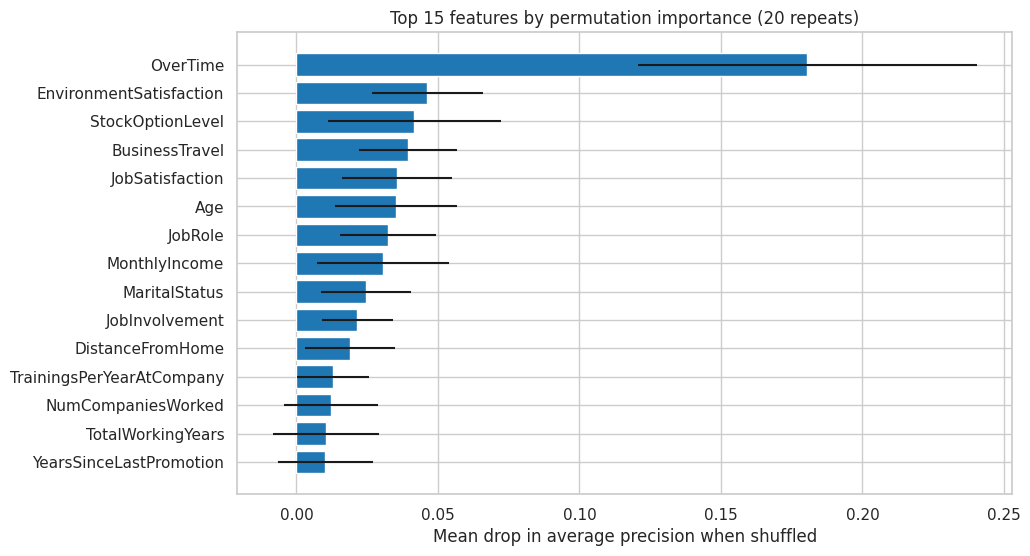

In [40]:
permutation = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_df = (
    pd.DataFrame(
        {
            "Feature": X_test.columns,
            "Mean drop in AP": permutation.importances_mean,
            "Std": permutation.importances_std,
        }
    )
    .sort_values("Mean drop in AP", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Mean drop in AP"],
    xerr=importance_df["Std"],
    color="tab:blue",
)
plt.gca().invert_yaxis()
plt.xlabel("Mean drop in average precision when shuffled")
plt.title(f"Top 15 features by permutation importance ({PERMUTATION_REPEATS} repeats)")
plt.show()

**Insight 17: Overtime dominates the model; satisfaction, stock options, travel, age, role and pay form a second tier.**

- **Finding.** Shuffling `OverTime` lowers the test average precision by about 0.18, roughly four times more than any other feature. The second tier (about 0.03–0.05 each) is EnvironmentSatisfaction, StockOptionLevel, BusinessTravel, JobSatisfaction, Age, JobRole and MonthlyIncome, followed by MaritalStatus, JobInvolvement and DistanceFromHome (about 0.02). For TrainingsPerYearAtCompany, NumCompaniesWorked, TotalWorkingYears and YearsSinceLastPromotion (about 0.01), the error bars reach zero. Values are read from the chart.
- **Fact check.** Direction comes from the labeled data: attrition is 31.9% with overtime vs. 10.8% without; 27.3% at Low environment satisfaction vs. 12.7% at Very High; 25.7% without stock options (level 0) vs. 7–15% with; 24.9% for frequent travelers vs. 10.3% for non-travelers; 26.7% for single employees vs. 9.5–13.4% for married or divorced ones; 40.0% at the lowest job involvement vs. 9.5% at the highest. Leavers are younger, earn less (Insight 12) and live slightly farther away (median 8 vs. 7). This ranking agrees with the chi-square results (Insight 13).
- **Caveats.** Importance measures reliance, not causation, and correlated features share it: tenure columns rank low partly because age, income and job role carry the same information (Insight 10). With 159 test employees, the ordering within the second tier is uncertain.
- **Modeling/business implication.** Overtime is both the strongest predictor and a directly manageable lever, followed by satisfaction, stock-option eligibility and travel load. These are the levers addressed in Recommendations 1–5 (Section 9.5).

### 7.6 Assessment against the Success Criteria

| ID | Criterion | Evidence | Status |
|---|---|---|---|
| B1 | Drivers reported with direction and statistical test | Insights 1–13 and statistical tests (Sections 4.4–4.5); permutation importance with direction (Insight 17) | **Met** |
| B2 | Risk score and flag for every employee without a recorded outcome, exported for the Streamlit app | 412 employees scored, 83 flagged (top 20%, iteration 2); `employee_risk_scores.csv` (Section 8.2) | **Met** |
| B3 | Voluntary vs. involuntary attrition | No reason-for-leaving field in the data | **Not met (data not available)** |
| D1 | Test ROC AUC ≥ 0.75 | 0.869 (Section 7.3) | **Met** |
| D2 | Test F2 > OverTime rule | 0.659 vs. 0.523 | **Met** |
| D3 | Average precision ≥ 2 × prevalence | 0.653 vs. 0.340 | **Met** |
| D4 | \|CV − test ROC AUC\| ≤ 0.05 | \|0.815 − 0.869\| = 0.054; test above CV | **Not met (marginal, favorable direction)** |

### 7.7 Process Review

**What worked**

- A single pipeline (encoding + model) fitted inside each fold prevents leakage and produced a deployable artifact.
- Benchmarks (majority class, overtime rule) make the model's value measurable: +8 leavers caught on the test set at similar precision.
- Optuna converged well within the budget (best trial 66 of 100), and the F2 threshold delivered the intended high recall.

**What to revisit**

- **Test-set size.** With 27 test leavers, one leaver shifts recall by 3.7 points, and the CV–test gap (D4) is within normal sampling variation. Iteration 2 uses repeated cross-validation (Section 7.9.1) and bootstrap confidence intervals (Section 7.9.4); the external validation (Section 8.3) adds 412 further employees.
- **Flag volume.** The low threshold flags 46.5% of test employees (74 of 159). Iteration 2 replaces it with a capacity-based cut-off: the top 20% of each scoring round (Section 7.9.3).
- **Calibration.** Probabilities should be checked before they are shown to HR as percentages; iteration 2 compares raw and calibrated probabilities (Section 7.9.2).
- **Engineered features.** They add little beyond the raw tenure columns (Insight 14); iteration 2 tests dropping them (Section 7.9.1).
- **Sensitive attributes.** The training-split screen removed Gender (Section 5.6), but MaritalStatus and Age are still inputs of the iteration-1 model. Iteration 2 tests dropping them (Section 7.9.1), and the flag rates per group are checked on the external set (Section 8.3).

### 7.8 Decision

| Outcome | Decision |
|---|---|
| D1–D4 all met | Deploy the model as a ranking tool for retention conversations (Section 8) |
| D2 or D3 not met | Do not deploy; use the overtime and work-life-balance rules from the EDA and collect more data |
| D1 or D4 not met, D2 and D3 met | Deploy for a limited pilot with HR review of every flag; revisit features and tuning |

**Decision (iteration 1): limited pilot, after a second iteration.** D1–D3 are met clearly and D4 is missed by 0.004 in the favorable direction, so the model qualifies for a one-quarter pilot in which HR Business Partners review every flagged employee. Before the pilot starts, iteration 2 (Section 7.9) addresses the five review points above.

### 7.9 Iteration 2: Addressing the Process Review

Iteration 2 works through the five review points in Section 7.7. Every choice is made **on the training split with cross-validation**; the test set is only used at the end (Section 7.9.4). Because that test set was already used once for iteration 1, the final result is a second look: it is reported with bootstrap confidence intervals, and the external validation in Section 8.3 gives an independent check on 412 employees the model has never seen.

| Review point | Change tested | Decision rule | Section |
|---|---|---|---|
| Test-set size | Repeated stratified CV (10 folds × 5 repeats) for all comparisons; bootstrap confidence intervals on the test set | — | 7.9.1, 7.9.4 |
| Feature screening | All features vs. the chi-square-screened set | Higher mean CV average precision | 7.9.1 |
| Engineered features | Drop the three engineered features | Drop if mean CV AP falls by ≤ 0.005 (`SIMPLICITY_TOLERANCE`) | 7.9.1 |
| Sensitive attributes | Drop Gender, MaritalStatus and Age | Drop if mean CV AP falls by ≤ 0.02 (`MAX_AP_LOSS_FOR_FAIRNESS`) | 7.9.1 |
| Calibration | Platt (sigmoid) calibration vs. raw probabilities | Use calibration if it lowers the out-of-fold Brier score | 7.9.2 |
| Flag volume | Flag the top 20% of each scoring round instead of the F2 threshold | Fixed by HR capacity (`REVIEW_CAPACITY_SHARE`) | 7.9.3 |

The hyperparameters from Section 6.4 are kept for all candidates, so the comparison isolates the effect of the feature set. They were tuned on the iteration-1 feature set, which gives that set a slight advantage.

#### 7.9.1 Feature-Set Candidates with Repeated Cross-Validation

*Repeated cross-validation* runs 10-fold cross-validation five times with different shuffles (50 fits per candidate), which averages out the luck of a single split. The interval shown is an approximate 95% interval for the mean; folds share training data, so it is somewhat too narrow and serves for comparison only.

In [41]:
repeated_cv = RepeatedStratifiedKFold(
    n_splits=CV_FOLDS, n_repeats=CV_REPEATS, random_state=RANDOM_STATE
)
all_candidate_cols = [
    col for col in labeled_df.columns if col != TARGET and col not in EXCLUDED_FEATURES
]
# Full-width splits (same employees as Section 5.5) so every candidate can pick columns.
X_train_all = labeled_df.loc[X_train.index, all_candidate_cols]
X_test_all = labeled_df.loc[X_test.index, all_candidate_cols]


def without(columns: Sequence[str], removed: Sequence[str]) -> list[str]:
    """Return ``columns`` without the names in ``removed``, keeping the order."""
    return [col for col in columns if col not in removed]


def repeated_cv_summary(name: str, columns: Sequence[str]) -> dict[str, Any]:
    """Score one feature set with repeated stratified cross-validation.

    Args:
        name: Label of the candidate.
        columns: Feature columns of the candidate.

    Returns:
        Mean average precision with an approximate 95% interval, mean ROC AUC
        and the number of features.
    """
    scores = cross_validate(
        build_pipeline(columns, **selected_params),
        X_train_all[list(columns)],
        y_train,
        cv=repeated_cv,
        scoring=CV_SCORING,
        n_jobs=-1,
    )
    ap = scores["test_average_precision"]
    half_width = 1.96 * ap.std(ddof=1) / np.sqrt(len(ap))
    return {
        "candidate": name,
        "n_features": len(columns),
        "ap_mean": ap.mean(),
        "ap_ci_low": ap.mean() - half_width,
        "ap_ci_high": ap.mean() + half_width,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
    }


candidate_rows = []
decisions = []

# Step 1: chi-square-screened set (iteration 1) vs. all features.
step1 = {
    "A. Iteration 1 feature set": feature_cols,
    "B. All features": all_candidate_cols,
}
step1_scores = {name: repeated_cv_summary(name, cols) for name, cols in step1.items()}
candidate_rows += step1_scores.values()
base_name = max(step1_scores, key=lambda name: step1_scores[name]["ap_mean"])
current_cols, current_summary = list(step1[base_name]), step1_scores[base_name]
decisions.append(f"Step 1: keep '{base_name}' (higher mean AP).")

# Step 2: drop engineered features if the loss is negligible.
cols = without(current_cols, ENGINEERED_COLS)
row = repeated_cv_summary("C. Step 1 without engineered features", cols)
candidate_rows.append(row)
if row["ap_mean"] >= current_summary["ap_mean"] - SIMPLICITY_TOLERANCE:
    current_cols, current_summary = cols, row
    decisions.append("Step 2: engineered features dropped.")
else:
    decisions.append("Step 2: engineered features kept.")

# Step 3: drop sensitive attributes if the loss stays within the fairness budget.
cols = without(current_cols, SENSITIVE_FEATURES)
row = repeated_cv_summary("D. Step 2 without Gender, MaritalStatus, Age", cols)
candidate_rows.append(row)
if row["ap_mean"] >= current_summary["ap_mean"] - MAX_AP_LOSS_FOR_FAIRNESS:
    current_cols, current_summary = cols, row
    decisions.append("Step 3: sensitive attributes dropped.")
else:
    decisions.append("Step 3: sensitive attributes kept (AP loss above budget).")

final_cols, final_cv_summary = current_cols, current_summary
display(pd.DataFrame(candidate_rows).set_index("candidate").round(4))
print("\n".join(decisions))
print(f"Final feature set: {len(final_cols)} features")

,n_features,ap_mean,ap_ci_low,ap_ci_high,roc_auc_mean
candidate,,,,,
A. Iteration 1 feature set,27,0.5889,0.5589,0.6189,0.8082
B. All features,33,0.5839,0.5532,0.6145,0.8054
C. Step 1 without engineered features,24,0.5849,0.5552,0.6146,0.8076
"D. Step 2 without Gender, MaritalStatus, Age",22,0.5899,0.5599,0.6199,0.8038


Step 1: keep 'A. Iteration 1 feature set' (higher mean AP).
Step 2: engineered features dropped.
Step 3: sensitive attributes dropped.
Final feature set: 22 features


**Insight 20: All four feature sets perform the same within noise, so the smallest and fairest set is kept: 22 features without engineered features, MaritalStatus and Age.**

- **Finding.** With the hyperparameters from Section 6.4 fixed, the mean CV average precision over 50 fits is 0.589 for the chi-square-screened set (A, 27 features), 0.584 for all features (B, 33), 0.585 without the engineered features (C, 24) and 0.590 without MaritalStatus and Age (D, 22; Gender had already been removed by the screen). The approximate 95% intervals all lie between about 0.55 and 0.62 and overlap almost completely; ROC AUC ranges from 0.804 to 0.808.
- **Fact check.** Step 1 keeps set A, Step 2 drops the engineered features (loss 0.004, within the 0.005 tolerance) and Step 3 drops MaritalStatus and Age (AP *increases* by 0.005, well within the 0.02 budget).
- **Caveats.** The repeated-CV average precision (about 0.59) is lower than the best Optuna trial (0.604) because the best of 100 trials is selected on the same folds and is therefore optimistic. Removing MaritalStatus and Age does not remove the information they carry: all 352 labeled employees whose marital status is Single have `StockOptionLevel = 0` (computed from the raw data), and age is closely tied to career length and job level (Insight 10), so the fairness effect has to be checked on the flags (Section 8.3).
- **Modeling/business implication.** The final model uses 22 features and no derived or sensitive attributes, which makes it simpler to explain, to maintain and to defend in an HR setting, at no measurable cost in accuracy.

#### 7.9.2 Probability Calibration

A model is *calibrated* when its probabilities match observed frequencies: among employees scored at 30%, about 30% should leave. Gradient Boosting probabilities are often too extreme or too timid. *Platt scaling* (sigmoid calibration) fits a small logistic curve on held-out folds that maps raw scores to calibrated probabilities. The comparison uses *out-of-fold* predictions (each training employee is scored by a model that did not see them) and the *Brier score*, the mean squared difference between predicted probability and outcome (lower is better).

,brier_score,average_precision,mean_probability
Raw,0.1081,0.5486,0.1608
Calibrated (sigmoid),0.1063,0.5552,0.1707


Use calibration: True (observed share of leavers: 0.169)


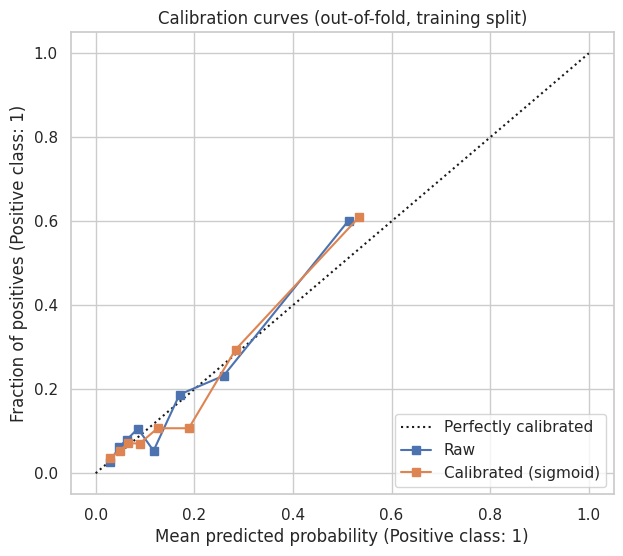

In [42]:
def build_candidate(columns: Sequence[str], calibrate: bool):
    """Build the final pipeline, optionally wrapped in sigmoid calibration.

    Args:
        columns: Feature columns of the candidate.
        calibrate: Whether to wrap the pipeline in ``CalibratedClassifierCV``.

    Returns:
        An unfitted estimator with ``predict_proba``.
    """
    pipeline = build_pipeline(columns, **selected_params)
    if not calibrate:
        return pipeline
    return CalibratedClassifierCV(
        pipeline, method=CALIBRATION_METHOD, cv=CALIBRATION_CV
    )


def oof_probabilities(estimator, X: pd.DataFrame, y: pd.Series) -> np.ndarray:
    """Return out-of-fold probabilities of leaving from ``cv_folds``."""
    return cross_val_predict(
        estimator, X, y, cv=cv_folds, method="predict_proba", n_jobs=-1
    )[:, 1]


X_train_final = X_train_all[final_cols]
oof = {
    "Raw": oof_probabilities(
        build_candidate(final_cols, False), X_train_final, y_train
    ),
    "Calibrated (sigmoid)": oof_probabilities(
        build_candidate(final_cols, True), X_train_final, y_train
    ),
}
calibration_table = pd.DataFrame(
    {
        name: {
            "brier_score": brier_score_loss(y_train, proba),
            "average_precision": average_precision_score(y_train, proba),
            "mean_probability": proba.mean(),
        }
        for name, proba in oof.items()
    }
).T
display(calibration_table.round(4))

use_calibration = (
    calibration_table.loc["Calibrated (sigmoid)", "brier_score"]
    < calibration_table.loc["Raw", "brier_score"]
)
final_oof = oof["Calibrated (sigmoid)" if use_calibration else "Raw"]
print(
    f"Use calibration: {use_calibration} "
    f"(observed share of leavers: {y_train.mean():.3f})"
)

fig, ax = plt.subplots(figsize=(7, 6))
for name, proba in oof.items():
    CalibrationDisplay.from_predictions(
        y_train, proba, n_bins=8, strategy="quantile", name=name, ax=ax
    )
ax.set(title="Calibration curves (out-of-fold, training split)")
plt.show()

**Result.** Sigmoid calibration lowers the out-of-fold Brier score slightly, from 0.1081 to 0.1063, and brings the mean predicted probability (0.171) closer to the observed share of leavers (0.169) than the raw model (0.161); out-of-fold average precision also rises slightly (0.549 to 0.555). Calibration is therefore used. Both curves follow the diagonal closely at low and medium risk; in the highest-risk bin, employees with a predicted risk of about 0.52–0.53 left in about 60% of cases, so the model slightly understates the risk of its top-ranked employees. The improvement is small, but it makes the displayed probabilities honest enough to show to HR as approximate percentages.

#### 7.9.3 Capacity-Based Flagging

Instead of flagging everyone above the F2 threshold, HR reviews the **top 20%** of each scoring round (`REVIEW_CAPACITY_SHARE`). The table shows, on out-of-fold predictions, what different capacities would deliver: the share of employees reviewed, the share of leavers among them (precision) and the share of all leavers found (recall). The F2 threshold from Section 6.6 is included for comparison. For single-employee checks in the app, the 20% capacity is translated into a probability cut-off: the 80th percentile of the out-of-fold probabilities.

In [43]:
def flag_summary(y_true: pd.Series, flags: np.ndarray) -> dict[str, float]:
    """Summarize a set of 0/1 flags: share flagged, precision and recall."""
    return {
        "flagged_share": float(np.mean(flags)),
        "precision": precision_score(y_true, flags, zero_division=0),
        "recall": recall_score(y_true, flags),
    }


capacity_rows = {
    f"Top {share:.0%}": flag_summary(
        y_train, (final_oof >= np.quantile(final_oof, 1 - share)).astype(int)
    )
    for share in CAPACITY_GRID
}
# Approximate: the F2 threshold was tuned on the iteration-1 feature set.
f2_flags = (oof["Raw"] >= final_model.best_threshold_).astype(int)
capacity_rows["F2 threshold (iteration 1)"] = flag_summary(y_train, f2_flags)
display(pd.DataFrame(capacity_rows).T.round(3))

capacity_threshold = float(np.quantile(final_oof, 1 - REVIEW_CAPACITY_SHARE))
print(
    f"Probability cut-off for the top {REVIEW_CAPACITY_SHARE:.0%}: "
    f"{capacity_threshold:.3f}"
)

,flagged_share,precision,recall
Top 10%,0.100,0.656,0.388
Top 20%,0.200,0.489,0.579
Top 30%,0.300,0.393,0.697
Top 40%,0.400,0.319,0.757
F2 threshold (iteration 1),0.553,0.260,0.849


Probability cut-off for the top 20%: 0.268


**Result.** On out-of-fold predictions, reviewing the top 10% finds 39% of all leavers with a precision of 66%; the **top 20% finds 58% of leavers with a precision of 49%** (about one in two reviews reaches a future leaver); 30% and 40% raise recall to 70% and 76% at precisions of 39% and 32%. The iteration-1 F2 threshold would flag 55% of employees to find 85% of leavers, at a precision of only 26%. The top-20% probability cut-off is 0.268. The chosen capacity is a business decision: widening the list from 10% to 20% adds 19 percentage points of recall, while each further 10% adds only 6–12 points, so 20% sits near the point of diminishing returns and can be widened once the pilot shows how many conversations are feasible.

#### 7.9.4 Final Candidate on the Test Set (Second Look)

The final candidate (feature set from 7.9.1, calibration from 7.9.2, cut-off from 7.9.3) is trained on the full training split and scored on the test set. *Bootstrap confidence intervals* resample the 159 test employees 1,000 times with replacement and recompute each metric, which shows how much the result could move with a different sample of employees. The same intervals are computed for iteration 1.

In [44]:
def bootstrap_ci(
    y_true: pd.Series, y_score: np.ndarray, y_pred: np.ndarray, n_boot: int
) -> pd.DataFrame:
    """Estimate 95% bootstrap confidence intervals for the test metrics.

    Args:
        y_true: Actual outcomes.
        y_score: Predicted probabilities of leaving.
        y_pred: 0/1 flags.
        n_boot: Number of bootstrap resamples.

    Returns:
        2.5th and 97.5th percentiles of ROC AUC, average precision, recall and
        precision across resamples (resamples with only one class are skipped).
    """
    rng = np.random.default_rng(RANDOM_STATE)
    y_true = np.asarray(y_true)
    rows = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        rows.append(
            {
                "roc_auc": roc_auc_score(y_true[idx], y_score[idx]),
                "average_precision": average_precision_score(y_true[idx], y_score[idx]),
                "recall": recall_score(y_true[idx], y_pred[idx]),
                "precision": precision_score(y_true[idx], y_pred[idx], zero_division=0),
            }
        )
    return (
        pd.DataFrame(rows)
        .quantile([0.025, 0.975])
        .T.set_axis(["ci_low", "ci_high"], axis=1)
    )


iteration2_model = FixedThresholdClassifier(
    build_candidate(final_cols, use_calibration), threshold=capacity_threshold
).fit(X_train_final, y_train)
y_test_proba_2 = iteration2_model.predict_proba(X_test_all[final_cols])[:, 1]
y_test_pred_2 = iteration2_model.predict(X_test_all[final_cols])

final_test = pd.Series(classification_summary(y_test, y_test_pred_2, y_test_proba_2))
comparison = pd.DataFrame(
    {"Iteration 1 (F2 threshold)": gb_test, "Iteration 2 (top 20%)": final_test}
).T
display(comparison.round(3))

intervals = pd.concat(
    {
        "Iteration 1": bootstrap_ci(y_test, y_test_proba, y_test_pred, N_BOOTSTRAP),
        "Iteration 2": bootstrap_ci(y_test, y_test_proba_2, y_test_pred_2, N_BOOTSTRAP),
    },
    names=["Model", "Metric"],
)
display(intervals.round(3))

,accuracy,precision,recall,f1,f2,flagged_share,roc_auc,average_precision
Iteration 1 (F2 threshold),0.667,0.324,0.889,0.475,0.659,0.465,0.869,0.653
Iteration 2 (top 20%),0.862,0.593,0.593,0.593,0.593,0.170,0.852,0.663


ci_low  ci_high
Model       Metric                            
Iteration 1 roc_auc             0.779    0.938
            average_precision   0.470    0.812
            recall              0.750    1.000
            precision           0.219    0.430
Iteration 2 roc_auc             0.747    0.933
            average_precision   0.468    0.823
            recall              0.393    0.778
            precision           0.400    0.783

**Insight 21: Iteration 2 ranks as well as iteration 1 with fewer inputs, and its 20% review list is almost twice as precise.**

- **Finding.** On the 159 test employees, iteration 2 reaches ROC AUC **0.852** and average precision **0.663** (iteration 1: 0.869 and 0.653). It flags 27 employees (17.0%), of whom 16 are leavers: precision and recall are both **0.593**, F2 0.593, accuracy 86.2%. Iteration 1 flagged 74 employees (46.5%) to catch 24 leavers (precision 0.324, recall 0.889).
- **Fact check.** The bootstrap intervals for ranking quality overlap almost entirely: ROC AUC 0.779–0.938 (iteration 1) vs. 0.747–0.933 (iteration 2); average precision 0.470–0.812 vs. 0.468–0.823. Recall (0.750–1.000 vs. 0.393–0.778) and precision (0.219–0.430 vs. 0.400–0.783) differ because of the cut-off, by design.
- **Caveats.** The test set was already used for iteration 1, so this is a second look; the external validation (Section 8.3) is the independent check. The test review list is slightly shorter than 20% (17.0%) because the cut-off comes from training-split predictions. With 27 leavers, each one moves recall by 3.7 points.
- **Modeling/business implication.** Compared with the overtime rule on the same test set, iteration 2 catches the same 16 leavers with 27 instead of 45 reviews. Iteration 1 catches eight more leavers but needs 47 additional reviews to do so; under a fixed review capacity, iteration 2 is the more efficient tool.

#### 7.9.5 Updated Assessment and Decision

The criteria from Section 2.4 are re-checked for the final candidate. For D4, its repeated-CV ROC AUC from Section 7.9.1 is compared with the test ROC AUC. D2 compares F2 values at different cut-offs (17.0% of test employees flagged by iteration 2 vs. 28.3% by the overtime rule), so it is read together with the capacity table in Section 7.9.3.

In [45]:
criteria_results_2 = assess_criteria(
    final_test, rule_test, final_cv_summary["roc_auc_mean"], y_test.mean()
)
criteria_results_2.round(3)

,ID,Criterion,Value,Met
0,D1,Test ROC AUC >= 0.75,0.852,True
1,D2,Test F2 > OverTime rule (0.523),0.593,True
2,D3,Average precision >= 2 x prevalence (0.340),0.663,True
3,D4,|CV ROC AUC (0.804) - test ROC AUC| <= 0.05,0.048,True


**Result and decision.** All four criteria are met: ROC AUC 0.852 ≥ 0.75 (D1), F2 0.593 > 0.523 for the overtime rule (D2), average precision 0.663 ≥ 0.340 (D3), and the gap between repeated-CV ROC AUC (0.804) and test ROC AUC is 0.048 ≤ 0.05 (D4), which resolves the D4 miss of iteration 1. D2 is met with a shorter list than the rule uses (17% vs. 28% flagged). **Decision: the iteration-2 candidate replaces iteration 1 and goes to the one-quarter pilot described in Section 7.8** (calibrated Gradient Boosting on 22 features, top 20% of each scoring round reviewed by HR Business Partners). The external validation in Section 8.3 confirms the decision (Insight 19).

## 8. Deployment

### 8.1 Refit on All Labeled Data

The final candidate from iteration 2 (feature set, calibration and capacity cut-off from Section 7.9) is refitted on **all 1,058 labeled employees** (train + test). The probability cut-off for the top 20% is recomputed from out-of-fold predictions on the same 1,058 employees, so single-employee checks in the app use the same capacity rule. The refit model has no held-out labeled data left, so its expected performance is the result from Section 7.9.4; Section 8.3 checks it on 412 employees it has never seen.

In [46]:
X_all = labeled_df[final_cols]
y_all = labeled_df[TARGET]

final_estimator = build_candidate(final_cols, use_calibration)
oof_all = oof_probabilities(final_estimator, X_all, y_all)
deployment_threshold = float(np.quantile(oof_all, 1 - REVIEW_CAPACITY_SHARE))
deployment_model = FixedThresholdClassifier(
    final_estimator, threshold=deployment_threshold
).fit(X_all, y_all)
print(
    f"Features: {len(final_cols)} | calibrated: {use_calibration} | "
    f"top-{REVIEW_CAPACITY_SHARE:.0%} cut-off: {deployment_threshold:.3f}"
)

Features: 22 | calibrated: True | top-20% cut-off: 0.262


The deployed model uses the 22 features from Section 7.9.1 with sigmoid calibration. On all 1,058 labeled employees, the top-20% probability cut-off is **0.262** (0.268 on the training split), so single-employee checks in the app flag an employee when the predicted risk reaches about 26%.

### 8.2 Score Employees without a Recorded Outcome

Each of the 412 employees without a recorded outcome receives a probability of leaving and a rank (1 = highest risk). The flag follows the capacity rule: the top 20% of this scoring round (83 employees) are flagged for review. A few descriptive columns are included so HR can read the list without joining tables.

In [47]:
review_slots = int(np.ceil(REVIEW_CAPACITY_SHARE * len(unlabeled_df)))
risk_scores = (
    unlabeled_df.assign(
        attrition_probability=deployment_model.predict_proba(unlabeled_df[final_cols])[
            :, 1
        ]
    )
    .assign(
        risk_rank=lambda d: (
            d["attrition_probability"].rank(ascending=False, method="first").astype(int)
        ),
        attrition_flag=lambda d: (d["risk_rank"] <= review_slots).astype(int),
    )
    .sort_values("risk_rank")[
        [
            "risk_rank",
            "attrition_probability",
            "attrition_flag",
            "Department",
            "JobRole",
            "JobLevel",
            "OverTime",
            "MonthlyIncome",
        ]
    ]
)

risk_scores.reset_index().to_csv(RISK_SCORES_PATH, index=False)
print(
    f"Flagged the top {review_slots} of {len(risk_scores)} employees; "
    f"saved to {RISK_SCORES_PATH.relative_to(PROJECT_ROOT)}"
)
risk_scores.head(10)

Flagged the top 83 of 412 employees; saved to data/processed/employee_risk_scores.csv


,risk_rank,attrition_probability,attrition_flag,Department,JobRole,JobLevel,OverTime,MonthlyIncome
EmployeeId,,,,,,,,
698,1,0.894915,1,Sales,Sales Representative,1,Yes,1569
1215,2,0.890533,1,Research & Development,Research Scientist,1,Yes,2439
949,3,0.864563,1,Research & Development,Laboratory Technician,1,Yes,3172
900,4,0.798641,1,Human Resources,Human Resources,1,Yes,2335
660,5,0.782694,1,Research & Development,Laboratory Technician,1,Yes,2074
1104,6,0.774826,1,Research & Development,Laboratory Technician,1,Yes,2398
792,7,0.764174,1,Sales,Sales Representative,1,Yes,2380
714,8,0.762064,1,Human Resources,Human Resources,1,No,2863
1152,9,0.754395,1,Research & Development,Research Scientist,1,Yes,2432


**Insight 18: The 83 employees on the review list match the risk profile found in the EDA.**

- **Finding.** The capacity rule flags the top 83 of the 412 employees (20%). The ten highest-ranked have calibrated probabilities between 0.74 and 0.89; all ten are at job level 1, nine work overtime, and all earn between 1,569 and 3,172 monetary units per month. They are Laboratory Technicians and Research Scientists in R&D (six), Sales Representatives (two) and Human Resources staff (two).
- **Caveats.** IBM's original file shows that 58 of these 412 employees left. Even a perfect ranking could therefore fill at most 58 of the 83 slots with leavers (precision of at most 0.70). Section 8.3 measures the actual performance.
- **Modeling/business implication.** The rank column lets HR extend the list if capacity allows; the capacity table (Section 7.9.3) shows what each additional 10% of reviews is expected to yield.

### 8.3 External Validation with IBM's Original Labels

The 412 employees without a recorded outcome have one in IBM's original file (Section 1). Matching each employee on every shared column recovers it, which turns these employees into an **external validation set**: the deployed model never saw them, and their outcomes were never used for any modeling choice. The same cell checks the flags against the **four-fifths rule** (29 C.F.R. § 1607.4(D)): if a group's flag rate is below 80% of the highest group's rate, the model is reviewed by HR and legal before wider use. The rule is a screening heuristic from employee selection, applied here to flag rates in both directions; a gap can also reflect genuine risk differences (e.g. by marital status, Insight 13), so it triggers a review rather than an automatic change.

In [48]:
def load_ibm_outcomes(url: str, cache_path: Path, reference: pd.DataFrame) -> pd.Series:
    """Recover IBM's original attrition outcome for every employee in ``reference``.

    Dicoding's file is IBM's file plus an ``EmployeeId`` column, with 412
    outcomes removed. Employees are matched on every column the two files
    share, which identifies each employee exactly once.

    Args:
        url: Public URL of IBM's original CSV file.
        cache_path: Local path where IBM's CSV is cached.
        reference: Dicoding data containing ``ID_COL`` and the shared columns.

    Returns:
        0/1 outcomes (1 = left) indexed by ``ID_COL``.

    Raises:
        ValueError: If an employee has no exact match in IBM's file.
    """
    ibm_data = load_employee_data(url, cache_path)
    keys = [
        col for col in reference.columns if col in ibm_data.columns and col != TARGET
    ]
    matched = reference[[ID_COL, *keys]].merge(
        ibm_data[[*keys, TARGET]], on=keys, how="left", validate="one_to_one"
    )
    if matched[TARGET].isna().any():
        raise ValueError("Some employees have no exact match in IBM's file.")
    return matched.set_index(ID_COL)[TARGET].map({"No": 0, "Yes": 1})


def flag_rate_ratios(flags: pd.Series, groups: pd.Series) -> pd.DataFrame:
    """Compare flag rates across groups using the four-fifths rule of thumb.

    Args:
        flags: 0/1 model flags indexed by employee.
        groups: Group label of each employee, with the same index.

    Returns:
        One row per group with its size, flag rate, ratio to the highest
        flag rate and whether that ratio is below ``FAIRNESS_MIN_RATIO``.
    """
    table = flags.groupby(groups, observed=True).agg(employees="size", flag_rate="mean")
    table["ratio_to_highest"] = table["flag_rate"] / table["flag_rate"].max()
    table["below_four_fifths"] = table["ratio_to_highest"] < FAIRNESS_MIN_RATIO
    return table


ibm_outcome = load_ibm_outcomes(IBM_DATA_URL, IBM_RAW_DATA_PATH, employee_data)
agreement = (ibm_outcome.loc[labeled_df.index] == labeled_df[TARGET]).mean()
print(f"Agreement with Dicoding's {len(labeled_df):,} known outcomes: {agreement:.1%}")

y_external = ibm_outcome.loc[risk_scores.index]
print(f"External set: {len(y_external)} employees, {y_external.sum()} leavers")
external_results = pd.DataFrame(
    {
        "Majority class (nobody leaves)": classification_summary(
            y_external, np.zeros(len(y_external), dtype=int)
        ),
        "Rule: OverTime == 'Yes'": classification_summary(
            y_external, (risk_scores["OverTime"] == "Yes").astype(int).to_numpy()
        ),
        "Gradient Boosting (deployed)": classification_summary(
            y_external,
            risk_scores["attrition_flag"].to_numpy(),
            risk_scores["attrition_probability"].to_numpy(),
        ),
    }
).T
display(external_results.round(3))

scored_profile = employee_data.set_index(ID_COL).loc[risk_scores.index]
fairness_groups = {
    "Gender": scored_profile["Gender"],
    "MaritalStatus": scored_profile["MaritalStatus"],
    "AgeBand": pd.cut(scored_profile["Age"], bins=AGE_BANDS),
}
fairness_report = pd.concat(
    {
        name: flag_rate_ratios(risk_scores["attrition_flag"], groups)
        for name, groups in fairness_groups.items()
    },
    names=["Attribute", "Group"],
)
display(fairness_report.round(3))

Agreement with Dicoding's 1,058 known outcomes: 100.0%
External set: 412 employees, 58 leavers


,accuracy,precision,recall,f1,f2,flagged_share,roc_auc,average_precision
Majority class (nobody leaves),0.859,0.000,0.000,0.000,0.000,0.000,NaN,NaN
Rule: OverTime == 'Yes',0.735,0.266,0.500,0.347,0.425,0.265,NaN,NaN
Gradient Boosting (deployed),0.847,0.470,0.672,0.553,0.619,0.201,0.828,0.616


employees  flag_rate  ratio_to_highest  \
Attribute     Group                                              
Gender        Female          150      0.200             0.989   
              Male            262      0.202             1.000   
MaritalStatus Divorced         85      0.129             0.318   
              Married         209      0.115             0.282   
              Single          118      0.407             1.000   
AgeBand       (17, 29]         90      0.400             1.000   
              (29, 39]        185      0.162             0.405   
              (39, 49]        106      0.123             0.307   
              (49, 60]         31      0.129             0.323   

                        below_four_fifths  
Attribute     Group                        
Gender        Female                False  
              Male                  False  
MaritalStatus Divorced               True  
              Married                True  
              Single                False  
AgeBand       (17, 29]              False  
              (29, 39]               True  
              (39, 49]               True  
              (49, 60]               True

**Insight 19: On 412 employees the model never saw, the ranking holds up and gender parity is reached, but flag rates still differ strongly by age and marital status.**

- **Finding.** Matched against IBM's file, Dicoding's 1,058 known outcomes agree 100%, and the 412 scored employees include 58 leavers. The deployed model reaches ROC AUC **0.828** and average precision **0.616** on them, close to its test-set values (0.852 and 0.663). Its review list of 83 employees (20.1%) contains 39 leavers: precision **0.470**, recall **0.672**, F2 0.619. The overtime rule on the same employees flags more people (26.5%) and catches fewer leavers (recall 0.500, precision 0.266, F2 0.425). Accuracy (84.7%) is slightly below the majority benchmark (85.9%), which is expected for a list built to catch leavers.
- **Fact check (fairness).** Women and men are flagged at the same rate (20.0% vs. 20.2%; ratio 0.99). Marital status and age still fail the four-fifths check: single employees are flagged at 40.7% vs. 11.5–12.9% for married and divorced employees (ratios 0.28–0.32), and employees under 30 at 40.0% vs. 12.3–16.2% for older groups (ratios 0.31–0.41). Actual attrition in the same 412 employees also differs (computed from IBM's file: single 22.0% vs. 10.5–11.8%; under 30 23.3% vs. 7.5–19.4%), but the flag gaps are wider than the outcome gaps.
- **Caveats.** MaritalStatus and Age are no longer inputs, so the remaining gaps come from correlated features: in the labeled data, every single employee has `StockOptionLevel = 0`, and age is tied to career length, tenure and job level. Women leave less often than men in this group (10.7% vs. 16.0%, computed from IBM's file) but are flagged at the same rate.
- **Modeling/business implication.** The external result confirms that the ranking generalizes, which supports the iteration-2 decision. The marital-status and age gaps trigger the HR/legal review defined in Section 8.4 before wider use: the review should decide whether stock-option eligibility (a company policy, Recommendation 3) should stay a model input, and whether to monitor flag rates against outcome rates per group rather than against the highest flag rate alone.

### 8.4 Save the Model, Its Metadata, the Input Schema and the Model Card

The fitted model (pipeline, optional calibration and capacity cut-off) is saved with `joblib` (the scikit-learn version must match when it is loaded again). Three JSON files accompany it:

- `model_metadata.json` (flat): what the model is, how it was built, its decision threshold and how well it performed, so the Streamlit app can display a model card and the next retraining can be compared against it.
- `feature_schema.json` (one flat record per feature): type, allowed categories and observed range of every input, so the app can build input forms and validate uploaded files.
- `model_card.json` (lists of flat records): the evaluation evidence that the app's model page needs but the metadata does not hold: criteria D1–D4 of iteration 2, test benchmarks against the majority class and the overtime rule, bootstrap intervals, external validation, the four-fifths fairness check and the permutation importance of the deployed configuration.

In [49]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(deployment_model, MODEL_PATH)

model_metadata = {
    "company": COMPANY_NAME,
    "disclaimer": DATA_DISCLAIMER,
    "model": "GradientBoostingClassifier + FixedThresholdClassifier",
    "iteration": 2,
    "calibrated": bool(use_calibration),
    "calibration_method": CALIBRATION_METHOD if use_calibration else "none",
    "decision_threshold": deployment_threshold,
    "threshold_objective": f"top {REVIEW_CAPACITY_SHARE:.0%} review capacity",
    "n_features": len(final_cols),
    "features": ", ".join(final_cols),
    "excluded_features": ", ".join(sorted(set(all_candidate_cols) - set(final_cols))),
    "trained_on_rows": len(X_all),
    "cv_average_precision": final_cv_summary["ap_mean"],
    "cv_roc_auc": final_cv_summary["roc_auc_mean"],
    **{f"test_{name}": value for name, value in final_test.items()},
    **{f"param_{name}": value for name, value in selected_params.items()},
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "created_at_utc": datetime.now(UTC).isoformat(timespec="seconds"),
}
save_json(model_metadata, MODEL_METADATA_PATH)


def describe_feature(column: str, values: pd.Series) -> dict[str, Any]:
    """Summarize one model input for form building and upload validation.

    Args:
        column: Feature name.
        values: Observed values of the feature in the labeled data.

    Returns:
        Flat record with the feature kind, allowed categories (nominal
        features, joined with ``|``) or the observed min/median/max.
    """
    if column in NOMINAL_COLS:
        return {
            "feature": column,
            "kind": "nominal",
            "categories": "|".join(sorted(values.dropna().astype(str).unique())),
        }
    kind = (
        "ordinal"
        if column in ORDINAL_COLS
        else "engineered"
        if column in ENGINEERED_COLS
        else "numeric"
    )
    return {
        "feature": column,
        "kind": kind,
        "min": float(values.min()),
        "median": float(values.median()),
        "max": float(values.max()),
    }


feature_schema = [describe_feature(col, X_all[col]) for col in final_cols]
save_json(feature_schema, FEATURE_SCHEMA_PATH)
print(
    f"Saved {MODEL_PATH.name}, {MODEL_METADATA_PATH.name} and "
    f"{FEATURE_SCHEMA_PATH.name} to {MODEL_DIR.relative_to(PROJECT_ROOT)}/"
)

Saved gradient_boosting_pipeline.joblib, model_metadata.json and feature_schema.json to artifacts/trained_models/


In [50]:
# Evaluation results for the Streamlit page "How the Model Works" that
# model_metadata.json does not hold. All values come from earlier sections, except the
# permutation importance, which repeats Section 7.5 for the iteration-2 configuration
# (same features, calibration and cut-off as the deployed model, trained on the
# training split and measured on the test split).
def to_records(frame: pd.DataFrame) -> list[dict[str, Any]]:
    """Convert a table to JSON-safe records (NumPy types to Python, NaN to null).

    Args:
        frame: Table with one row per record and simple column names.

    Returns:
        One dictionary per row.
    """
    return json.loads(frame.to_json(orient="records"))


def model_rows(table: pd.DataFrame) -> pd.DataFrame:
    """Move the model names of a metrics table from the index into a ``model`` column."""
    return table.rename_axis("model").reset_index()


def group_label(group: object) -> str:
    """Label a fairness group; age bands such as ``(17, 29]`` become ``'18-29'``."""
    if isinstance(group, pd.Interval):
        return f"{int(group.left) + 1}-{int(group.right)}"
    return str(group)


permutation_2 = permutation_importance(
    iteration2_model,
    X_test_all[final_cols],
    y_test,
    scoring="average_precision",
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_2 = pd.DataFrame(
    {
        "feature": final_cols,
        "mean_drop_ap": permutation_2.importances_mean,
        "std": permutation_2.importances_std,
    }
).sort_values("mean_drop_ap", ascending=False, ignore_index=True)

test_benchmarks = pd.concat(
    [
        test_results.rename(index={test_results.index[-1]: "Gradient Boosting (iteration 1)"}),
        final_test.rename("Gradient Boosting (iteration 2)").to_frame().T,
    ]
)
fairness_rows = (
    fairness_report.reset_index()
    .rename(columns={"Attribute": "attribute", "Group": "group"})
    .assign(group=lambda d: d["group"].map(group_label))
)

model_card = {
    "company": COMPANY_NAME,
    "disclaimer": DATA_DISCLAIMER,
    "review_capacity_share": REVIEW_CAPACITY_SHARE,
    "test_employees": len(y_test),
    "test_leavers": int(y_test.sum()),
    "external_employees": len(y_external),
    "external_leavers": int(y_external.sum()),
    "fairness_min_ratio": FAIRNESS_MIN_RATIO,
    "permutation_repeats": PERMUTATION_REPEATS,
    "criteria": to_records(criteria_results_2.rename(columns=str.lower)),
    "test_benchmarks": to_records(model_rows(test_benchmarks)),
    "test_intervals": to_records(intervals.reset_index().rename(columns=str.lower)),
    "external_validation": to_records(model_rows(external_results)),
    "fairness": to_records(fairness_rows),
    "permutation_importance": to_records(importance_2),
    "created_at_utc": datetime.now(UTC).isoformat(timespec="seconds"),
}
save_json(model_card, MODEL_CARD_PATH)
print(f"Saved {MODEL_CARD_PATH.name} to {MODEL_CARD_PATH.parent.relative_to(PROJECT_ROOT)}/")
importance_2.head(10).round(4)

Saved model_card.json to artifacts/trained_models/


,feature,mean_drop_ap,std
0,OverTime,0.2143,0.0657
1,StockOptionLevel,0.1216,0.0389
2,EnvironmentSatisfaction,0.0687,0.0214
3,MonthlyIncome,0.0587,0.0281
4,JobRole,0.0476,0.0139
5,BusinessTravel,0.0462,0.0170
6,TotalWorkingYears,0.0420,0.0269
7,JobSatisfaction,0.0401,0.0169
8,JobLevel,0.0308,0.0191
9,DistanceFromHome,0.0301,0.0157


**Result: The deployed configuration relies on the same main lever as iteration 1, but stock-option eligibility moves clearly into second place.**

- **Finding.** Shuffling `OverTime` lowers the test average precision by 0.21 (± 0.07), still by far the largest drop. `StockOptionLevel` follows at 0.12 (± 0.04), well ahead of its position in iteration 1 (Insight 17). The second tier is EnvironmentSatisfaction (0.07), MonthlyIncome (0.06), JobRole and BusinessTravel (about 0.05 each), TotalWorkingYears and JobSatisfaction (about 0.04). The table shows the top 10 of 22 inputs; in the full ranking saved to `model_card.json`, seven inputs add nothing measurable, with a mean drop within one standard deviation of zero or below zero: YearsAtCompany, TrainingTimesLastYear, DailyRate, MonthlyRate, HourlyRate, PercentSalaryHike and WorkLifeBalance.
- **Interpretation.** Removing MaritalStatus and Age (Section 7.9.1) moves part of their information to correlated inputs: all 470 employees whose marital status is Single have `StockOptionLevel` 0 (computed from the raw data), and `TotalWorkingYears` correlates with age (r = 0.68). This is consistent with the remaining flag-rate gaps by marital status and age band (Insight 19). WorkLifeBalance shows a strong rate at "Bad" in the EDA (32.1%), but only 56 labeled employees have that rating, which likely leaves too few cases to change the ranking once overtime and satisfaction are known.
- **Caveats.** Importance measures reliance, not causation. With 159 test employees (27 leavers), the order within the second tier is uncertain. The values describe the iteration-2 configuration trained on the training split; the deployed model is the same configuration refit on all 1,058 labeled employees.
- **Use.** These values feed the model page of the Streamlit app (`permutation_importance` in `model_card.json`). Insight 17 remains the description of iteration 1.

**Serving.** The saved pipeline accepts raw employee records with the columns in `features`, so an app only needs to load it and call `predict_proba`:

```python
model = joblib.load("artifacts/trained_models/gradient_boosting_pipeline.joblib")
probabilities = model.predict_proba(new_employees[feature_cols])[:, 1]
```

**Intended use.** Scores are a prompt for a supportive conversation (stay interview, workload review, career discussion), never a basis for disciplinary action, pay decisions or dismissal.

**Monitoring.**

- Each quarter, compare predicted risk with actual departures (recall, precision, average precision) and with the metadata baseline.
- Track input drift in the key features (overtime share, income distribution, job-level mix).
- Retrain when recall on new departures falls below the overtime-rule benchmark or when the HR data model changes.
- Review flag rates by gender, age band and marital status each quarter with the four-fifths check from Section 8.3 (`FAIRNESS_MIN_RATIO = 0.8`). A ratio below 0.8 triggers an HR/legal review of the model and its inputs before the next scoring round.

### 8.5 Streamlit App: HR Dashboard and Prediction Prototype

One Streamlit app serves two purposes: a descriptive dashboard for HR and an interactive prototype of the predictive model. It reads only the files exported above, so it never retrains the model.

| Page | Purpose | Main user (Section 2.3) | Inputs |
|---|---|---|---|
| Workforce Insights | Headcount, attrition rate and rates by department, job role, job level, overtime and work-life balance; income distribution of leavers vs. stayers | Department heads, HR Director | `employee.csv` |
| Retention Review List | Unlabeled employees ranked by risk, with filters (department, role, overtime) and a CSV download | HR Business Partners | `employee_risk_scores.csv` |
| Check an Employee | Single-employee tab: form → probability, flag at the top-20% cut-off and a what-if comparison (e.g. without overtime). Batch tab: upload a CSV with the schema columns → validated, scored file | HR Business Partners, People Analytics team | model, `feature_schema.json`, `model_metadata.json` |
| How the Model Works | Test metrics vs. criteria D1–D4, external validation, threshold, Optuna summary, intended use and disclaimer | All | `model_metadata.json`, `model_card.json`, `optuna_best_params.json` |

**Preprocessing and decision order for new records** (identical to training):

1. Validate columns and values against `feature_schema.json` (unknown categories are allowed; the encoder maps them to all zeros).
2. No feature engineering is needed: the final feature set (Section 7.9.1) uses only original columns, so the app passes raw employee records straight to the model.
3. Select the columns in `features` and call `predict_proba` on the saved pipeline (encoding happens inside it).
4. For a batch, flag the top 20% by rank; for a single employee, flag when the probability reaches `decision_threshold` (the top-20% cut-off), which `predict` applies automatically.

**Presentation rules.** Every page and every download carries the disclaimer in `DATA_DISCLAIMER`. Probabilities are shown as percentages only if calibration is used (Section 7.9.2); otherwise as risk bands or ranks. The app uses MurphysBio's own brand palette and logo.

## 9. Conclusion & Recommendations

### 9.1 Conclusion

**In one sentence:** attrition in the fictional MurphysBio workforce is concentrated among employees who work overtime, are early in their careers and paid less, sit at entry level, have no stock options or report low satisfaction, and a calibrated Gradient Boosting model that reviews the top 20% of employees finds 59% of the leavers on the test set (precision 0.59) and 67% of the leavers among 412 employees it never saw (precision 0.47).

- **G1 (drivers):** overtime (31.9% vs. 10.8% attrition) is the strongest factor, in the statistical tests and in the model (Insight 17). Job level 1 (27.4%), lower income (leaver median 3,388 vs. 5,210 monetary units), an early-career profile (younger, shorter career and tenure; Section 4.5.1), no stock options (25.7%), frequent travel (24.9%), single marital status (26.7%), "Bad" work-life balance (32.1%) and low environment or job satisfaction are also significantly associated with leaving. Department, gender, education and performance rating show no significant association.
- **G2 (prediction):** iteration 1 (100 Optuna trials, saved as flat JSON) reached test ROC AUC 0.869 at an F2 threshold but flagged almost half of all employees and missed D4. Iteration 2 keeps the same ranking quality with 22 features, sigmoid calibration and a top-20% review list: test ROC AUC 0.852, average precision 0.663, precision and recall 0.593, all criteria D1–D4 met. On 412 external employees it reaches ROC AUC 0.828, precision 0.470 and recall 0.672 (Insight 19).
- **G3 (reason for leaving):** not achievable, because neither data source records why an employee left.

### 9.2 Were the Problem Statements Answered?

- **PS1:** Yes (B1): the EDA summary (Section 4.6), the numeric and chi-square tests (Sections 4.5.1–4.5.2) and the permutation importance with direction of effect (Insight 17) agree on overtime as the main driver and on a second tier of satisfaction, stock options, travel, age, role and pay.
- **PS2:** Yes (B2, D1–D4 met in iteration 2): the model ranks employees clearly better than the overtime rule, on the test set and on 412 external employees (Insights 21 and 19), and the review list is exported for the Streamlit app.
- **PS3:** No (B3): requires a reason-for-leaving field.

### 9.3 Goals vs. Criteria

| Goal | Criteria | Result | Status |
|---|---|---|---|
| G1 | B1, D4 | 21 insights with statistical tests, permutation importance and external validation; D4 gap 0.048 in iteration 2 | Met |
| G2 | B2, D1, D2, D3 | Iteration 2: ROC AUC 0.852, F2 0.593 vs. 0.523, AP 0.663 vs. 0.340; 83 of 412 employees on the review list; external ROC AUC 0.828 | Met |
| G3 | B3 | No reason-for-leaving data | Not met |

### 9.4 Impact of the Approach

- Measuring the model against an overtime rule answers the business question "is the model better than what HR could do with one filter?": on the test set, the final model finds the same 16 leavers with 27 instead of 45 reviews, and on the 412 external employees it finds 39 leavers where the rule finds 29, with fewer reviews.
- Keeping the 412 employees without a recorded outcome turns the project from a retrospective analysis into a forward-looking tool, and IBM's original labels make it possible to test that tool on employees the model has never seen.
- A leakage-safe pipeline, a fixed set of success criteria and a pilot decision rule make the result auditable for HR and reusable for the Streamlit app.

### 9.5 Recommendations

| # | Recommendation | Evidence | Owner |
|---|---|---|---|
| 1 | Review overtime allocation in teams with high overtime and high predicted risk; set an overtime cap or compensation policy | Overtime roughly triples the attrition rate (31.9% vs. 10.8%) and dominates the model (Insights 13, 17) | Department heads |
| 2 | Run stay interviews each quarter with the top 20% of the risk list (Section 8.2), starting with Sales and Level 1 roles; extend the list by rank if capacity allows | Highest-ranked flags are the most precise (Section 7.4); Sales and Level 1 have the highest rates (Insights 1, 7) | HR Business Partners |
| 3 | Benchmark pay within job level and department; prioritize employees below their group's median; review stock-option eligibility for Level 1–2 | Leavers earn less than stayers in every department-gender group (Insight 6); 25.7% attrition without stock options (Insight 17) | HR Director / Compensation team |
| 4 | Define a clear promotion path out of Level 1 (e.g. review after a fixed number of years) | Level 1 attrition 27.4% vs. 5–15% above (Insight 7); early-career profile (Insight 12) | HR Director / Compensation team |
| 5 | Add a follow-up conversation whenever an employee rates work-life balance or environment satisfaction as the lowest level, and review frequent-travel assignments | 32.1% attrition at "Bad" work-life balance, 27.3% at Low environment satisfaction, 24.9% for frequent travelers (Insights 3, 17) | HR Business Partners, Department heads |
| 6 | Record the reason for leaving and the exit date for every departure; retrain quarterly and run the four-fifths fairness check | Enables PS3, time-aware validation and fairness monitoring (Sections 8.3–8.4) | Data / People Analytics team |
| 7 | Review with HR/legal whether stock-option eligibility should remain a model input, and monitor flag rates against outcome rates by marital status and age band each quarter | Remaining four-fifths gaps act through correlated features (Insight 19) | Data / People Analytics team, HR Director |

### 9.6 Limitations

- **Fictional data and company.** The dataset follows IBM's fictional HR Analytics schema, and MurphysBio is an illustrative name chosen to fit its job roles and education fields; patterns cannot be transferred to a real company without retraining on its own data.
- **Withheld rather than unknown outcomes.** The 412 employees "without a recorded outcome" are, in reality, employees whose labels Dicoding removed; their outcomes are known in IBM's file and are used only for validation (Section 8.3).
- **Single snapshot, no dates.** The model cannot say *when* someone will leave, and validation cannot be time-ordered.
- **Small minority class.** About 180 leavers (27 in the test set) limit how precisely metrics can be estimated (Section 7.7).
- **Undocumented units.** Monetary columns have no documented currency, so pay findings are relative.
- **Associations, not causes.** Neither the statistical tests nor permutation importance establish causality; interventions should be piloted and measured.
- **Sensitive attributes.** Gender, MaritalStatus and Age are not inputs of the deployed model (Section 7.9.1), but flag rates by marital status and age band still fail the four-fifths check through correlated features such as `StockOptionLevel` (Insight 19), so the model needs an HR/legal review before wider use.

Process-related limitations are listed in the process review (Section 7.7).